<a href="https://colab.research.google.com/github/Maryvictor/titanic-kaggle/blob/version-1.0/titanic_kaggle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Titanic: Machine Learning from Disaster

> *Quem teria sobrevivido ao naufrágio do Titanic, e por quê?*

**Autora:** Maria Victor  |  **Fonte dos dados:** Kaggle  |  **Início:** outubro de 2026

---

## 1. Contexto

Em 15 de abril de 1912, o RMS Titanic afundou em sua viagem inaugural, depois de colidir com um iceberg no Atlântico Norte. Dos mais de 2.200 a bordo, pouco mais de 700 sobreviveram. A tragédia não foi totalmente aleatória: algumas pessoas tiveram mais chances do que outras, e é isso que os dados nos ajudam a enxergar.

## 2. Objetivo

Construir um modelo de *machine learning* capaz de prever se um passageiro sobreviveu ou não (`Survived`), a partir de características como idade, sexo, classe da passagem e família a bordo.

Mais do que acertar a previsão, a ideia deste notebook é **aprender o caminho**: entender os dados, levantar hipóteses, testar e explicar o que encontramos.

## 3. Os dados

| Coluna | O que significa | Observação |
|---|---|---|
| `PassengerId` | Identificador do passageiro | Só um código, sem valor preditivo |
| `Survived` | Sobreviveu? | **Alvo:** 0 = não, 1 = sim |
| `Pclass` | Classe da passagem | 1 = alta, 2 = média, 3 = baixa |
| `Name` | Nome do passageiro | Guarda pistas, como o título (Mr, Mrs, Miss) |
| `Sex` | Sexo | male ou female |
| `Age` | Idade em anos | Tem valores ausentes |
| `SibSp` | Irmãos e cônjuges a bordo | Número inteiro |
| `Parch` | Pais e filhos a bordo | Número inteiro |
| `Ticket` | Número do bilhete | Texto livre |
| `Fare` | Valor pago pela passagem | Em libras da época |
| `Cabin` | Número da cabine | Muitos valores ausentes |
| `Embarked` | Porto de embarque | C = Cherbourg, Q = Queenstown, S = Southampton |



## 4. Carregando os dados

Aqui trazemos o arquivo `train.csv` do Kaggle para dentro do notebook, num **DataFrame** (uma tabela do pandas). Ele tem 891 passageiros e 12 colunas.

Dois cuidados que aprendemos pelo caminho:

- Ler o arquivo por uma planilha do Google estragou alguns números da coluna de tarifa, como `1.465.208` no lugar de `146.5208`. Mais para frente consertamos isso usando o arquivo original do Kaggle.
- Os nomes das colunas estão em inglês. Vamos traduzir para facilitar a leitura.

In [ ]:
import io
import pandas as pd
import gspread
from google.colab import auth
from google.auth import default

# Autentica no Google
auth.authenticate_user()

# Pega credenciais com os escopos certos para Drive e Sheets
creds, _ = default(scopes=[
    'https://www.googleapis.com/auth/spreadsheets',
    'https://www.googleapis.com/auth/drive'
])

gc = gspread.Client(auth=creds)

# Abre o arquivo pelo nome
sh = gc.open('train')


In [ ]:
# Pega a primeira aba e converte pra DataFrame
df = pd.DataFrame(sh.sheet1.get_all_records())

print(f'Shape: {df.shape}')
df

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22,1,0,A/5 21171,7.25,,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38,1,0,PC 17599,712.833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26,0,0,STON/O2. 3101282,7.925,,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35,1,0,113803,53.1,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35,0,0,373450,8.05,,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27,0,0,211536,13,,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19,0,0,112053,30,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,,1,2,W./C. 6607,23.45,,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26,0,0,111369,30,C148,C


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   PassengerId  891 non-null    int64 
 1   Survived     891 non-null    int64 
 2   Pclass       891 non-null    int64 
 3   Name         891 non-null    object
 4   Sex          891 non-null    object
 5   Age          891 non-null    object
 6   SibSp        891 non-null    int64 
 7   Parch        891 non-null    int64 
 8   Ticket       891 non-null    object
 9   Fare         891 non-null    object
 10  Cabin        891 non-null    object
 11  Embarked     891 non-null    object
dtypes: int64(5), object(7)
memory usage: 83.7+ KB


In [ ]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

## 5. Arrumando a casa

**Nomes em português.** Trocamos `Survived` por `sobreviveu`, `Pclass` por `classe` e assim por diante. Isso não muda os dados, só deixa o código mais fácil de ler.

**Classe invertida.** No arquivo original, a classe 1 é a mais cara (alta) e a 3 é a mais barata (baixa). Isso confunde, porque "1" parece "o menor". Invertemos para que **1 = baixa, 2 = média, 3 = alta**. Assim, quanto maior o número, maior o status.

> Atenção: no `test.csv` do Kaggle a classe vem do jeito original. Quando chegarmos lá, precisamos aplicar a mesma inversão.

In [ ]:
# Dicionário: nome antigo -> nome novo
colunas_pt = {
    'PassengerId': 'id_passageiro',
    'Survived':    'sobreviveu',
    'Pclass':      'classe',
    'Name':        'nome',
    'Sex':         'sexo',
    'Age':         'idade',
    'SibSp':       'irmaos_conjuge',
    'Parch':       'pais_filhos',
    'Ticket':      'bilhete',
    'Fare':        'tarifa',
    'Cabin':       'cabine',
    'Embarked':    'porto_embarque'
}

# Aplica a troca
df = df.rename(columns=colunas_pt)

# Confere se deu certo
df.columns

Index(['id_passageiro', 'sobreviveu', 'classe', 'nome', 'sexo', 'idade',
       'irmaos_conjuge', 'pais_filhos', 'bilhete', 'tarifa', 'cabine',
       'porto_embarque'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id_passageiro   891 non-null    int64 
 1   sobreviveu      891 non-null    int64 
 2   classe          891 non-null    int64 
 3   nome            891 non-null    object
 4   sexo            891 non-null    object
 5   idade           891 non-null    object
 6   irmaos_conjuge  891 non-null    int64 
 7   pais_filhos     891 non-null    int64 
 8   bilhete         891 non-null    object
 9   tarifa          891 non-null    object
 10  cabine          891 non-null    object
 11  porto_embarque  891 non-null    object
dtypes: int64(5), object(7)
memory usage: 83.7+ KB


In [ ]:
# Confere: quantos passageiros em cada classe (1 = baixa, 3 = alta)
df['classe'].value_counts().sort_index()

,count
classe,
1,216
2,184
3,491


In [ ]:
# Inverte a classe: 1 vira 3, 2 continua 2, 3 vira 1
df['classe'] = df['classe'].map({1: 3, 2: 2, 3: 1})

# Confere: quantos passageiros em cada classe (1 = baixa, 3 = alta)
df['classe'].value_counts().sort_index()

,count
classe,
1,491
2,184
3,216


## 6. Quantos valores diferentes cada coluna tem?

Antes de mexer, olhamos cada coluna: quantos valores únicos ela tem e quais são. Isso mostra rápido quem é **identificador** (`id_passageiro`, `nome`), quem é **categoria** (`sexo`, `classe`, `porto_embarque`) e quem é **número** (`idade`, `tarifa`).

O que isso nos avisou:

- `idade` tem valores vazios.
- `cabine` e `porto_embarque` também têm vazios.
- `tarifa` tem textos esquisitos, como `1.465.208`.

In [ ]:
df.nunique().sort_values()

,0
sobreviveu,2
sexo,2
classe,3
porto_embarque,4
pais_filhos,7
irmaos_conjuge,7
idade,89
cabine,148
tarifa,248
bilhete,681


In [ ]:
for coluna in df.columns:
    qtd = df[coluna].nunique()
    print(f"\n{coluna}  ({qtd} valores únicos)")

    if qtd <= 15:
        print(df[coluna].unique())
    else:
        print("Muitos valores, mostrando só os 100 primeiros:")
        print(df[coluna].unique()[:150])


id_passageiro  (891 valores únicos)
Muitos valores, mostrando só os 100 primeiros:
[  1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107 108
 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125 126
 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143 144
 145 146 147 148 149 150]

sobreviveu  (2 valores únicos)
[0 1]

classe  (3 valores únicos)
[1 3 2]

nome  (891 valores únicos)
Muitos valores, mostrando só os 100 primeiros:
['Braund, Mr. Owen Harris'
 'Cumings, Mrs. John Bradley (Florence Briggs Thayer)'
 'Heikkinen, Miss. Laina' 'Futrelle, Mrs. Jacques Heath (Lily May Peel)'
 '

In [ ]:
# Pega só a coluna de nomes (com o id, pra você saber quem é quem)
nomes = df[['id_passageiro', 'nome']]

# Salva o CSV
nomes.to_csv('nomes_titanic.csv', index=False, encoding='utf-8-sig')

# Baixa o arquivo para o seu computador
from google.colab import files
files.download('nomes_titanic.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Texto vazio vira "Desconhecido"

- **Bilhete** é um código sem significado para o modelo, então saiu naquele momento (depois voltamos a usá-lo de outro jeito, para contar quantas pessoas dividiam o mesmo bilhete).
- **Porto de embarque**: `C`, `Q` e `S` viraram Cherbourg, Queenstown e Southampton. Criamos também o país (França, Irlanda, Inglaterra).
- **Cabine**: tem muitos vazios (a maioria não tem cabine registrada). Separamos a **letra** (o andar do navio) do **número** da cabine.
- **Sexo**: traduzido para Masculino e Feminino.

Em vez de apagar quem não tem informação, escrevemos "Desconhecido". Assim a pessoa continua na análise.

In [ ]:
df = df.drop(columns=['bilhete'])

In [ ]:
df['porto_embarque'] = df['porto_embarque'].replace('', 'Desconhecido')

In [ ]:
df['porto_embarque'] = df['porto_embarque'].replace({
    'C': 'Cherbourg',
    'Q': 'Queenstown',
    'S': 'Southampton'
})

In [ ]:
df['porto_embarque'].value_counts(dropna=False)

,count
porto_embarque,
Southampton,644
Cherbourg,168
Queenstown,77
Desconhecido,2


In [ ]:
df['pais_embarque'] = df['porto_embarque'].map({
    'Cherbourg': 'França',
    'Queenstown': 'Irlanda',
    'Southampton': 'Inglaterra',
    'Desconhecido': 'Desconhecido'
})

In [ ]:
df[['porto_embarque', 'pais_embarque']].drop_duplicates()

,porto_embarque,pais_embarque
0,Southampton,Inglaterra
1,Cherbourg,França
5,Queenstown,Irlanda
61,Desconhecido,Desconhecido


In [ ]:
df['cabine'] = df['cabine'].replace('', 'Desconhecido')

In [ ]:
df['cabine'].value_counts(dropna=False)

,count
cabine,
Desconhecido,687
G6,4
C23 C25 C27,4
B96 B98,4
F2,3
...,...
E17,1
A24,1
C50,1


In [ ]:
df['cabine'].value_counts(dropna=False).loc[lambda x: x >= 2]

,count
cabine,
Desconhecido,687
G6,4
C23 C25 C27,4
B96 B98,4
F2,3
D,3
E101,3
C22 C26,3
F33,3


In [ ]:
import re


def extrair_cabine(valor):
    if pd.isna(valor) or str(valor).strip() in ['', 'Desconhecido']:
        return pd.Series({
            'cabine_letras': 'Desconhecido',
            'cabine_numeros': 'Desconhecido'
        })

    # Extrai todas as letras que antecedem números
    letras = re.findall(r'[A-Za-z]+(?=\d)', str(valor))

    # Extrai todos os números
    numeros = re.findall(r'\d+', str(valor))

    return pd.Series({
        'cabine_letras': ' '.join(letras) if letras else 'Desconhecido',
        'cabine_numeros': ' '.join(numeros) if numeros else 'Desconhecido'
    })

df[['cabine_letras', 'cabine_numeros']] = df['cabine'].apply(extrair_cabine)

In [ ]:
df['cabine_letras'].value_counts(dropna=False)

,count
cabine_letras,
Desconhecido,691
C,51
B,36
E,33
D,29
A,15
F,9
G,7
B B,7


In [ ]:
df['cabine_numeros'].value_counts(dropna=False)

,count
cabine_numeros,
Desconhecido,691
33,7
6,6
49,5
2,5
...,...
11,1
82 84,1
102,1


In [ ]:
df['cabine_letras'] = df['cabine_letras'].apply(
    lambda x: ' '.join(dict.fromkeys(x.split()))
    if x != 'Desconhecido' else x
)

In [ ]:
df['cabine_letras'].value_counts(dropna=False)

,count
cabine_letras,
Desconhecido,691
C,59
B,47
E,33
D,30
A,15
F,9
G,7


In [ ]:
df['cabine_numeros'].value_counts(dropna=False).loc[lambda x: x >= 2]

,count
cabine_numeros,
Desconhecido,691
33,7
6,6
49,5
2,5
101,5
20,5
23 25 27,4
35,4


In [ ]:
df['cabine_numeros'] = df['cabine_numeros'].apply(
    lambda x: '/'.join(x.split())
    if x != 'Desconhecido' else x
)

In [ ]:
df['cabine_numeros'].value_counts(dropna=False).loc[lambda x: x >= 2]

,count
cabine_numeros,
Desconhecido,691
33,7
6,6
49,5
2,5
101,5
20,5
23/25/27,4
35,4


In [ ]:
for coluna in df.columns:
    qtd = df[coluna].nunique()
    print(f"\n{coluna}  ({qtd} valores únicos)")

    if qtd <= 15:
        print(df[coluna].unique())
    else:
        print("Muitos valores, mostrando só os 100 primeiros:")
        print(df[coluna].unique()[:250])


id_passageiro  (891 valores únicos)
Muitos valores, mostrando só os 100 primeiros:
[  1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107 108
 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125 126
 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143 144
 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161 162
 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179 180
 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197 198
 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215 216
 217 218 219 220 221 222 223 224 225 226

In [ ]:
df['sexo'] = df['sexo'].replace({
    'male': 'Masculino',
    'female': 'Feminino'
})

## 8. Agrupando idade e tarifa em faixas

Agrupamos a idade em faixas (bebê, criança, adolescente, jovem adulto, adulto, meia-idade e 60 anos ou mais) para enxergar padrões nos gráficos.

A tarifa foi dividida em 4 faixas com o mesmo número de pessoas (os **quartis**). A conta de corrigir valores como `1.465.208` entrou aqui, e depois foi refeita com o arquivo original.

In [ ]:
import numpy as np

# Converte a coluna 'idade' para numérico, transformando textos inválidos em NaN
df['idade'] = pd.to_numeric(df['idade'], errors='coerce')

faixas = [0, 1, 12, 18, 30, 45, 60, np.inf]

categorias = [
    'Bebê (0 a menos de 1 ano)',
    'Criança (1 a 11 anos)',
    'Adolescente (12 a 17 anos)',
    'Jovem adulto (18 a 29 anos)',
    'Adulto (30 a 44 anos)',
    'Meia-idade (45 a 59 anos)',
    '60 anos ou mais'
]

df['faixa_etaria'] = pd.cut(
    df['idade'],
    bins=faixas,
    labels=categorias,
    right=False
)

df['faixa_etaria'] = (
    df['faixa_etaria']
    .cat.add_categories('Desconhecido')
    .fillna('Desconhecido')
)

# Confere a distribuição final das faixas etárias
df['faixa_etaria'].value_counts()

,count
faixa_etaria,
Jovem adulto (18 a 29 anos),271
Adulto (30 a 44 anos),215
Desconhecido,177
Meia-idade (45 a 59 anos),89
Criança (1 a 11 anos),61
Adolescente (12 a 17 anos),45
60 anos ou mais,26
Bebê (0 a menos de 1 ano),7


In [ ]:


def corrigir_tarifa(valor):
    if pd.isna(valor) or str(valor).strip() == '':
        return np.nan

    valor = str(valor).strip()

    # Valores com dois pontos, como '1.465.208'
    if valor.count('.') == 2:
        digitos = re.sub(r'\D', '', valor)
        return int(digitos) / 10000

    return pd.to_numeric(valor, errors='coerce')


df['tarifa_num'] = df['tarifa'].apply(corrigir_tarifa)

In [ ]:
df['faixa_tarifa'] = pd.qcut(
    df['tarifa_num'],
    q=4,
    labels=[
        'Tarifa baixa (0,00 – 7,91)',
        'Tarifa média-baixa (7,91 – 15,50)',
        'Tarifa média-alta (15,50 – 55,90)',
        'Tarifa alta (55,90 – 910,79)'
    ],
    duplicates='drop'
)

In [ ]:
df.columns

Index(['id_passageiro', 'sobreviveu', 'classe', 'nome', 'sexo', 'idade',
       'irmaos_conjuge', 'pais_filhos', 'tarifa', 'cabine', 'porto_embarque',
       'pais_embarque', 'cabine_letras', 'cabine_numeros', 'faixa_etaria',
       'tarifa_num', 'faixa_tarifa'],
      dtype='object')

In [ ]:
df = df[[
    # Identificação
    'id_passageiro', 'nome',

    # Sobrevivência
    'sobreviveu',

    # Perfil pessoal
    'sexo', 'idade', 'faixa_etaria',

    # Família
    'irmaos_conjuge', 'pais_filhos',

    # Viagem
    'classe', 'cabine', 'cabine_letras', 'cabine_numeros',

    # Tarifa
    'tarifa', 'tarifa_num', 'faixa_tarifa',

    # Embarque
    'porto_embarque', 'pais_embarque',
]]

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   id_passageiro   891 non-null    int64   
 1   nome            891 non-null    object  
 2   sobreviveu      891 non-null    int64   
 3   sexo            891 non-null    object  
 4   idade           714 non-null    float64 
 5   faixa_etaria    891 non-null    category
 6   irmaos_conjuge  891 non-null    int64   
 7   pais_filhos     891 non-null    int64   
 8   classe          891 non-null    int64   
 9   cabine          891 non-null    object  
 10  cabine_letras   891 non-null    object  
 11  cabine_numeros  891 non-null    object  
 12  tarifa          891 non-null    object  
 13  tarifa_num      891 non-null    float64 
 14  faixa_tarifa    891 non-null    category
 15  porto_embarque  891 non-null    object  
 16  pais_embarque   891 non-null    object  
dtypes: category(2), 

In [ ]:
df['id_passageiro'] = df['id_passageiro'].astype(str)

In [ ]:
df.describe()

,sobreviveu,idade,irmaos_conjuge,pais_filhos,classe,tarifa_num
count,891.000000,714.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,29.699118,0.523008,0.381594,1.691358,82.400463
std,0.486592,14.526497,1.102743,0.806057,0.836071,163.454034
min,0.000000,0.420000,0.000000,0.000000,1.000000,0.000000
25%,0.000000,20.125000,0.000000,0.000000,1.000000,7.910400
50%,0.000000,28.000000,0.000000,0.000000,1.000000,15.500000
75%,1.000000,38.000000,1.000000,0.000000,2.000000,55.900000
max,1.000000,80.000000,8.000000,6.000000,3.000000,910.792000


## 9. O título dentro do nome

O nome do passageiro guarda uma pista: `Braund, Mr. Owen Harris`. O pedaço entre a vírgula e o ponto (**Mr**, **Mrs**, **Miss**, **Master**, **Dr**...) é o **título**.

Isso vale ouro porque o título conta **sexo, estado civil e até idade aproximada**. Por exemplo, "Master" era um menino. Traduzimos para o português na coluna `titulo_pt`.

In [ ]:
# 1. Extrai o título: o que vem entre a vírgula e o primeiro ponto
df['titulo'] = df['nome'].str.extract(r',\s*([^.]+)\.')

# Confere quais títulos apareceram
df['titulo'].value_counts()

,count
titulo,
Mr,517
Miss,182
Mrs,125
Master,40
Dr,7
Rev,6
Col,2
Mlle,2
Major,2


In [ ]:
traducao = {
    'Mr':           'Senhor',
    'Mrs':          'Senhora',
    'Miss':         'Senhorita',
    'Master':       'Menino',
    'Mme':          'Senhora',        # Madame, em francês
    'Mlle':         'Senhorita',      # Mademoiselle, em francês
    'Ms':           'Sra./Srta.',     # forma neutra, sem indicar estado civil
    'Dr':           'Doutor',
    'Rev':          'Reverendo',
    'Col':          'Coronel',
    'Major':        'Major',
    'Capt':         'Capitão',
    'Don':          'Dom',
    'Sir':          'Cavaleiro',      # título britânico de honra
    'Lady':         'Dama',           # esposa de um Sir
    'the Countess': 'Condessa',
    'Jonkheer':     'Fidalgo'         # baixa nobreza holandesa
}

df['titulo_pt'] = df['titulo'].map(traducao)

# A única médica: Dr. Alice Leader
df.loc[(df['titulo'] == 'Dr') & (df['sexo'] == 'female'), 'titulo_pt'] = 'Doutora'

# Confere: não pode aparecer NaN
df['titulo_pt'].value_counts(dropna=False)

,count
titulo_pt,
Senhor,517
Senhorita,184
Senhora,126
Menino,40
Doutor,7
Reverendo,6
Major,2
Coronel,2
Dom,1


In [ ]:
sem_idade = df[df['idade'].isna()]

print(len(sem_idade), 'passageiros sem idade')
sem_idade.head(20)

177 passageiros sem idade


,id_passageiro,nome,sobreviveu,sexo,idade,faixa_etaria,irmaos_conjuge,pais_filhos,classe,cabine,cabine_letras,cabine_numeros,tarifa,tarifa_num,faixa_tarifa,porto_embarque,pais_embarque,titulo,titulo_pt
5,6,"Moran, Mr. James",0,Masculino,NaN,Desconhecido,0,0,1,Desconhecido,Desconhecido,Desconhecido,8.4583,8.4583,"Tarifa média-baixa (7,91 – 15,50)",Queenstown,Irlanda,Mr,Senhor
17,18,"Williams, Mr. Charles Eugene",1,Masculino,NaN,Desconhecido,0,0,2,Desconhecido,Desconhecido,Desconhecido,13,13.0000,"Tarifa média-baixa (7,91 – 15,50)",Southampton,Inglaterra,Mr,Senhor
19,20,"Masselmani, Mrs. Fatima",1,Feminino,NaN,Desconhecido,0,0,1,Desconhecido,Desconhecido,Desconhecido,7.225,7.2250,"Tarifa baixa (0,00 – 7,91)",Cherbourg,França,Mrs,Senhora
26,27,"Emir, Mr. Farred Chehab",0,Masculino,NaN,Desconhecido,0,0,1,Desconhecido,Desconhecido,Desconhecido,7.225,7.2250,"Tarifa baixa (0,00 – 7,91)",Cherbourg,França,Mr,Senhor
28,29,"O'Dwyer, Miss. Ellen ""Nellie""",1,Feminino,NaN,Desconhecido,0,0,1,Desconhecido,Desconhecido,Desconhecido,7.8792,7.8792,"Tarifa baixa (0,00 – 7,91)",Queenstown,Irlanda,Miss,Senhorita
29,30,"Todoroff, Mr. Lalio",0,Masculino,NaN,Desconhecido,0,0,1,Desconhecido,Desconhecido,Desconhecido,7.8958,7.8958,"Tarifa baixa (0,00 – 7,91)",Southampton,Inglaterra,Mr,Senhor
31,32,"Spencer, Mrs. William Augustus (Marie Eugenie)",1,Feminino,NaN,Desconhecido,1,0,3,B78,B,78,1.465.208,146.5208,"Tarifa alta (55,90 – 910,79)",Cherbourg,França,Mrs,Senhora
32,33,"Glynn, Miss. Mary Agatha",1,Feminino,NaN,Desconhecido,0,0,1,Desconhecido,Desconhecido,Desconhecido,7.75,7.7500,"Tarifa baixa (0,00 – 7,91)",Queenstown,Irlanda,Miss,Senhorita
36,37,"Mamee, Mr. Hanna",1,Masculino,NaN,Desconhecido,0,0,1,Desconhecido,Desconhecido,Desconhecido,7.2292,7.2292,"Tarifa baixa (0,00 – 7,91)",Cherbourg,França,Mr,Senhor
42,43,"Kraeff, Mr. Theodor",0,Masculino,NaN,Desconhecido,0,0,1,Desconhecido,Desconhecido,Desconhecido,7.8958,7.8958,"Tarifa baixa (0,00 – 7,91)",Cherbourg,França,Mr,Senhor


In [ ]:
df.columns

Index(['id_passageiro', 'nome', 'sobreviveu', 'sexo', 'idade', 'faixa_etaria',
       'irmaos_conjuge', 'pais_filhos', 'classe', 'cabine', 'cabine_letras',
       'cabine_numeros', 'tarifa', 'tarifa_num', 'faixa_tarifa',
       'porto_embarque', 'pais_embarque', 'titulo', 'titulo_pt'],
      dtype='object')

In [ ]:
nova_ordem = [
    # Quem é
    'id_passageiro', 'nome', 'titulo', 'titulo_pt',
    # O que queremos prever
    'sobreviveu',
    # Características da pessoa
    'sexo', 'idade', 'faixa_etaria',
    # Família a bordo
    'irmaos_conjuge', 'pais_filhos',
    # Classe e dinheiro
    'classe', 'tarifa', 'tarifa_num', 'faixa_tarifa',
    # Onde ficava no navio
    'cabine', 'cabine_letras', 'cabine_numeros',
    # De onde veio
    'porto_embarque', 'pais_embarque'
]

# Confere se nenhuma coluna ficou de fora ou foi repetida
faltando = set(df.columns) - set(nova_ordem)
sobrando = set(nova_ordem) - set(df.columns)
print('Faltando:', faltando, '| Sobrando:', sobrando)

df = df[nova_ordem]
df.head()

Faltando: set() | Sobrando: set()


,id_passageiro,nome,titulo,titulo_pt,sobreviveu,sexo,idade,faixa_etaria,irmaos_conjuge,pais_filhos,classe,tarifa,tarifa_num,faixa_tarifa,cabine,cabine_letras,cabine_numeros,porto_embarque,pais_embarque
0,1,"Braund, Mr. Owen Harris",Mr,Senhor,0,Masculino,22.0,Jovem adulto (18 a 29 anos),1,0,1,7.25,7.250,"Tarifa baixa (0,00 – 7,91)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra
1,2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,Senhora,1,Feminino,38.0,Adulto (30 a 44 anos),1,0,3,712.833,712.833,"Tarifa alta (55,90 – 910,79)",C85,C,85,Cherbourg,França
2,3,"Heikkinen, Miss. Laina",Miss,Senhorita,1,Feminino,26.0,Jovem adulto (18 a 29 anos),0,0,1,7.925,7.925,"Tarifa média-baixa (7,91 – 15,50)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra
3,4,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,Senhora,1,Feminino,35.0,Adulto (30 a 44 anos),1,0,3,53.1,53.100,"Tarifa média-alta (15,50 – 55,90)",C123,C,123,Southampton,Inglaterra
4,5,"Allen, Mr. William Henry",Mr,Senhor,0,Masculino,35.0,Adulto (30 a 44 anos),0,0,1,8.05,8.050,"Tarifa média-baixa (7,91 – 15,50)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra


In [ ]:
sem_idade = df[df['idade'].isna()]

print(len(sem_idade), 'passageiros sem idade')
#sem_idade.head(20)
print(sem_idade.to_string())

177 passageiros sem idade
    id_passageiro                                                nome  titulo  titulo_pt  sobreviveu       sexo  idade  faixa_etaria  irmaos_conjuge  pais_filhos  classe     tarifa  tarifa_num                       faixa_tarifa        cabine cabine_letras cabine_numeros porto_embarque pais_embarque
5               6                                    Moran, Mr. James      Mr     Senhor           0  Masculino    NaN  Desconhecido               0            0       1     8.4583      8.4583  Tarifa média-baixa (7,91 – 15,50)  Desconhecido  Desconhecido   Desconhecido     Queenstown       Irlanda
17             18                        Williams, Mr. Charles Eugene      Mr     Senhor           1  Masculino    NaN  Desconhecido               0            0       2         13     13.0000  Tarifa média-baixa (7,91 – 15,50)  Desconhecido  Desconhecido   Desconhecido    Southampton    Inglaterra
19             20                             Masselmani, Mrs. Fatima     

## Explorando em gráficos

A partir daqui olhamos os dados em gráficos. Nos gráficos de sobrevivência, usamos sempre a mesma leitura: **cor clara = morreu** e **cor forte = sobreviveu**. Quando aparece uma linha tracejada, ela marca a **média geral**, para comparar cada barra com o conjunto.

### Sexo

Primeira pergunta: como os passageiros se dividem por sexo, e quem morreu ou sobreviveu em cada grupo?

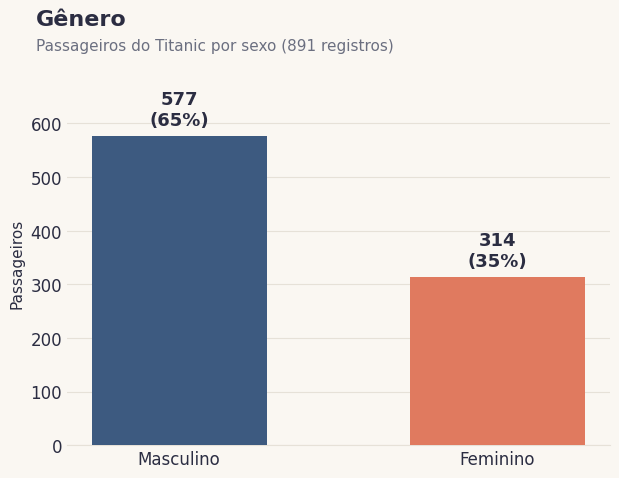

In [ ]:
import matplotlib.pyplot as plt

# Paleta do projeto: guarde isto no começo do notebook e reaproveite
COR_MASC  = '#3D5A80'   # azul petróleo
COR_FEM   = '#E07A5F'   # terracota
FUNDO     = '#FAF7F2'   # papel
TEXTO     = '#2B2D42'   # grafite
GRADE     = '#E6E1D8'   # cinza quente claro

paleta_sexo = {'Masculino': COR_MASC, 'Feminino': COR_FEM}

contagem = df['sexo'].value_counts()
total = contagem.sum()
cores = [paleta_sexo[s] for s in contagem.index]

fig, ax = plt.subplots(figsize=(7, 5), facecolor=FUNDO)
ax.set_facecolor(FUNDO)

ax.bar(contagem.index, contagem.values, color=cores, width=0.55, zorder=3)

# Números em cima das barras: quantidade e percentual
for i, v in enumerate(contagem.values):
    ax.text(i, v + 12, f'{v}\n({v/total:.0%})',
            ha='center', va='bottom', fontsize=13, fontweight='bold', color=TEXTO)

# Visual limpo
ax.set_ylim(0, contagem.max() * 1.18)
ax.yaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left']:
    ax.spines[lado].set_visible(False)
ax.spines['bottom'].set_color(GRADE)
ax.tick_params(colors=TEXTO, length=0, labelsize=12)

# Título e subtítulo alinhados à esquerda
fig.text(0.08, 0.95, 'Gênero', fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.08, 0.90, 'Passageiros do Titanic por sexo (891 registros)',
         fontsize=11, color='#6B6F80', ha='left')

ax.set_xlabel('')
ax.set_ylabel('Passageiros', color=TEXTO, fontsize=11)

plt.subplots_adjust(top=0.84)
plt.show()

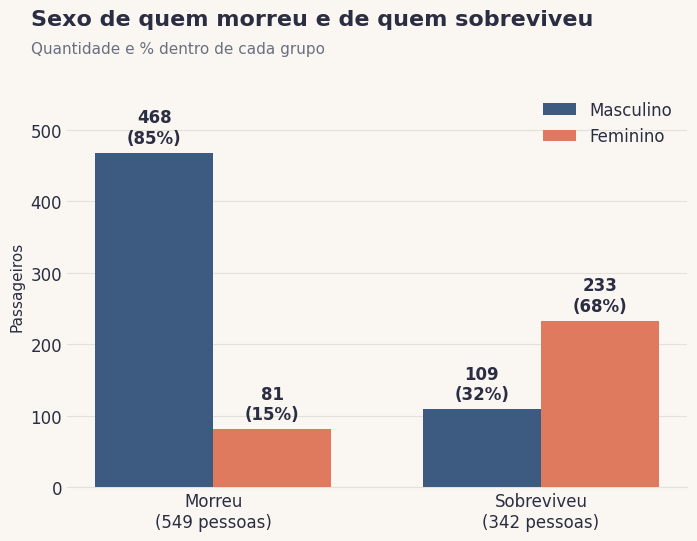

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tradução do 0 e do 1, sem criar coluna nova no df
destino = df['sobreviveu'].map({0: 'Morreu', 1: 'Sobreviveu'})

tab = pd.crosstab(destino, df['sexo'])
tab = tab.loc[['Morreu', 'Sobreviveu'], ['Masculino', 'Feminino']]
total_grupo = tab.sum(axis=1)

fig, ax = plt.subplots(figsize=(8, 5.5), facecolor=FUNDO)
ax.set_facecolor(FUNDO)

x = np.arange(len(tab))
larg = 0.36

for i, sexo in enumerate(['Masculino', 'Feminino']):
    posicao = x + (i - 0.5) * larg
    ax.bar(posicao, tab[sexo], larg, color=paleta_sexo[sexo], label=sexo, zorder=3)

    for px, v, tot in zip(posicao, tab[sexo], total_grupo):
        ax.text(px, v + 8, f'{v}\n({v/tot:.0%})', ha='center', va='bottom',
                fontsize=12, fontweight='bold', color=TEXTO)

ax.set_xticks(x)
ax.set_xticklabels([f'{g}\n({total_grupo[g]} pessoas)' for g in tab.index])
ax.set_ylim(0, tab.values.max() * 1.2)
ax.yaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left']:
    ax.spines[lado].set_visible(False)
ax.spines['bottom'].set_color(GRADE)
ax.tick_params(colors=TEXTO, length=0, labelsize=12)
ax.set_ylabel('Passageiros', color=TEXTO, fontsize=11)

# Legenda no canto direito, longe das barras altas
ax.legend(frameon=False, loc='upper right', fontsize=12, labelcolor=TEXTO)

# Título curto e neutro
fig.text(0.08, 0.95, 'Sexo de quem morreu e de quem sobreviveu',
         fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.08, 0.90, 'Quantidade e % dentro de cada grupo',
         fontsize=11, color='#6B6F80', ha='left')

plt.subplots_adjust(top=0.84)
plt.show()

In [ ]:
df.head()

,id_passageiro,nome,titulo,titulo_pt,sobreviveu,sexo,idade,faixa_etaria,irmaos_conjuge,pais_filhos,classe,tarifa,tarifa_num,faixa_tarifa,cabine,cabine_letras,cabine_numeros,porto_embarque,pais_embarque
0,1,"Braund, Mr. Owen Harris",Mr,Senhor,0,Masculino,22.0,Jovem adulto (18 a 29 anos),1,0,1,7.25,7.250,"Tarifa baixa (0,00 – 7,91)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra
1,2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,Senhora,1,Feminino,38.0,Adulto (30 a 44 anos),1,0,3,712.833,712.833,"Tarifa alta (55,90 – 910,79)",C85,C,85,Cherbourg,França
2,3,"Heikkinen, Miss. Laina",Miss,Senhorita,1,Feminino,26.0,Jovem adulto (18 a 29 anos),0,0,1,7.925,7.925,"Tarifa média-baixa (7,91 – 15,50)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra
3,4,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,Senhora,1,Feminino,35.0,Adulto (30 a 44 anos),1,0,3,53.1,53.100,"Tarifa média-alta (15,50 – 55,90)",C123,C,123,Southampton,Inglaterra
4,5,"Allen, Mr. William Henry",Mr,Senhor,0,Masculino,35.0,Adulto (30 a 44 anos),0,0,1,8.05,8.050,"Tarifa média-baixa (7,91 – 15,50)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra


### Idade por sexo

Comparamos como a idade se distribui entre homens e mulheres. Usamos a coluna `idade` original (sem preenchimento), para não misturar dados reais com estimados.

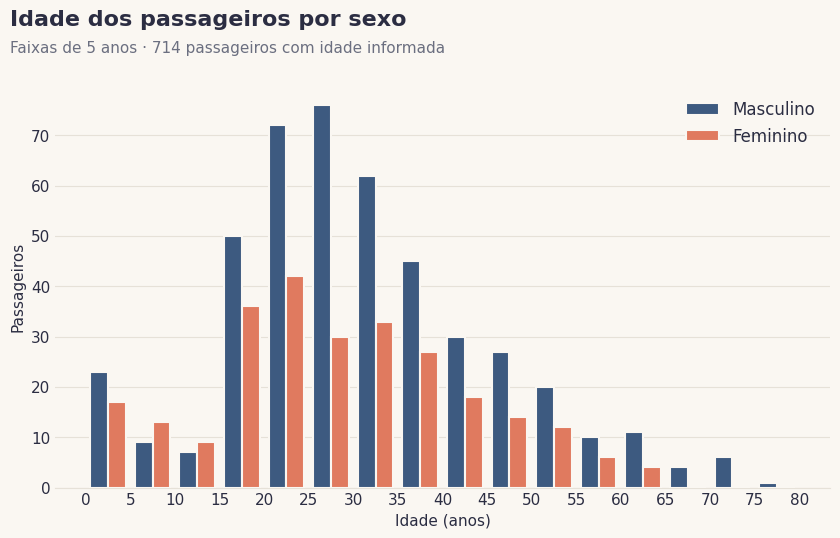

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Idades de cada sexo (quem não tem idade fica de fora)
masc = df.loc[df['sexo'] == 'Masculino', 'idade'].dropna()
fem  = df.loc[df['sexo'] == 'Feminino',  'idade'].dropna()

# Faixas de 5 em 5 anos: 0-5, 5-10, ... até 80
faixas = np.arange(0, 85, 5)

fig, ax = plt.subplots(figsize=(10, 5.5), facecolor=FUNDO)
ax.set_facecolor(FUNDO)

ax.hist([masc, fem], bins=faixas,
        color=[COR_MASC, COR_FEM], label=['Masculino', 'Feminino'],
        edgecolor=FUNDO, linewidth=1.5, zorder=3)

# Visual limpo
ax.set_xticks(faixas)
ax.set_xlabel('Idade (anos)', color=TEXTO, fontsize=11)
ax.set_ylabel('Passageiros', color=TEXTO, fontsize=11)
ax.yaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left']:
    ax.spines[lado].set_visible(False)
ax.spines['bottom'].set_color(GRADE)
ax.tick_params(colors=TEXTO, length=0, labelsize=11)

ax.legend(frameon=False, loc='upper right', fontsize=12, labelcolor=TEXTO)

# Título curto e neutro
n_com_idade = len(masc) + len(fem)
fig.text(0.08, 0.95, 'Idade dos passageiros por sexo',
         fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.08, 0.90, f'Faixas de 5 anos · {n_com_idade} passageiros com idade informada',
         fontsize=11, color='#6B6F80', ha='left')

plt.subplots_adjust(top=0.84)
plt.show()

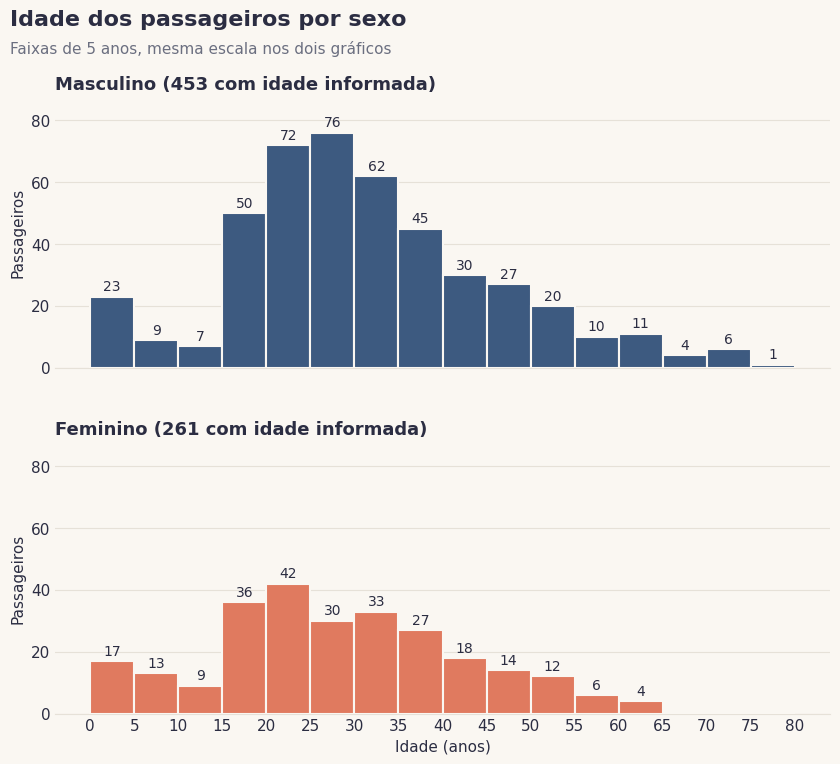

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

masc = df.loc[df['sexo'] == 'Masculino', 'idade'].dropna()
fem  = df.loc[df['sexo'] == 'Feminino',  'idade'].dropna()

faixas = np.arange(0, 85, 5)

# Dois gráficos empilhados, com os mesmos eixos
fig, axes = plt.subplots(2, 1, figsize=(10, 8), facecolor=FUNDO,
                         sharex=True, sharey=True)

# Altura da maior barra entre os dois, para os dois ficarem na mesma escala
topo = max(np.histogram(masc, faixas)[0].max(),
           np.histogram(fem,  faixas)[0].max())

for ax, dados, cor, nome in zip(axes, [masc, fem],
                                [COR_MASC, COR_FEM],
                                ['Masculino', 'Feminino']):
    ax.set_facecolor(FUNDO)

    contagem, _, barras = ax.hist(dados, bins=faixas, color=cor,
                                  edgecolor=FUNDO, linewidth=1.5, zorder=3)

    # Número em cima de cada barra (esconde os zeros)
    ax.bar_label(barras, labels=[int(c) if c > 0 else '' for c in contagem],
                 color=TEXTO, fontsize=10, padding=2)

    ax.set_ylim(0, topo * 1.15)
    ax.yaxis.grid(True, color=GRADE, zorder=0)
    for lado in ['top', 'right', 'left']:
        ax.spines[lado].set_visible(False)
    ax.spines['bottom'].set_color(GRADE)
    ax.tick_params(colors=TEXTO, length=0, labelsize=11)
    ax.set_ylabel('Passageiros', color=TEXTO, fontsize=11)
    ax.set_title(f'{nome} ({len(dados)} com idade informada)',
                 loc='left', color=TEXTO, fontsize=13, fontweight='bold')

axes[1].set_xticks(faixas)
axes[1].set_xlabel('Idade (anos)', color=TEXTO, fontsize=11)

fig.text(0.08, 0.97, 'Idade dos passageiros por sexo',
         fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.08, 0.935, 'Faixas de 5 anos, mesma escala nos dois gráficos',
         fontsize=11, color='#6B6F80', ha='left')

plt.subplots_adjust(top=0.88, hspace=0.28)
plt.show()

### Crianças e adolescentes

Crianças tinham prioridade nos botes? Olhamos quem tinha até 15 anos, separando por sexo e depois por classe.

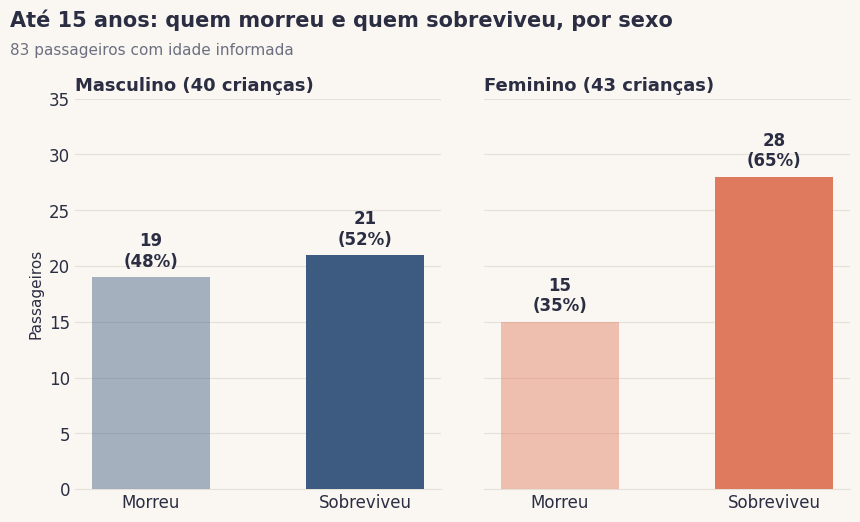

In [ ]:
import matplotlib.pyplot as plt

# Só quem tem 15 anos ou menos (quem não tem idade fica de fora)
criancas = df[df['idade'] <= 15]

fig, axes = plt.subplots(1, 2, figsize=(10, 5.5), facecolor=FUNDO, sharey=True)

# Altura da maior barra, para os dois gráficos ficarem na mesma escala
topo = criancas.groupby(['sexo', 'sobreviveu']).size().max()

for ax, sexo in zip(axes, ['Masculino', 'Feminino']):
    ax.set_facecolor(FUNDO)

    # Quantos morreram (0) e quantos sobreviveram (1) nesse sexo
    g = criancas[criancas['sexo'] == sexo]['sobreviveu'].value_counts()
    g = g.reindex([0, 1], fill_value=0)
    total = g.sum()

    barras = ax.bar(['Morreu', 'Sobreviveu'], g.values,
                    color=paleta_sexo[sexo], width=0.55, zorder=3)
    barras[0].set_alpha(0.45)   # "Morreu" mais clara, "Sobreviveu" forte

    # Número e percentual (dentro do sexo) em cima de cada barra
    for b, v in zip(barras, g.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.6, f'{v}\n({v/total:.0%})',
                ha='center', va='bottom', fontsize=12,
                fontweight='bold', color=TEXTO)

    ax.set_ylim(0, topo * 1.25)
    ax.yaxis.grid(True, color=GRADE, zorder=0)
    for lado in ['top', 'right', 'left']:
        ax.spines[lado].set_visible(False)
    ax.spines['bottom'].set_color(GRADE)
    ax.tick_params(colors=TEXTO, length=0, labelsize=12)
    ax.set_title(f'{sexo} ({total} crianças)', loc='left',
                 color=TEXTO, fontsize=13, fontweight='bold')

axes[0].set_ylabel('Passageiros', color=TEXTO, fontsize=11)

fig.text(0.06, 0.95, 'Até 15 anos: quem morreu e quem sobreviveu, por sexo',
         fontsize=15, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.06, 0.90, f'{len(criancas)} passageiros com idade informada',
         fontsize=11, color='#6B6F80', ha='left')

plt.subplots_adjust(top=0.82, wspace=0.12)
plt.show()

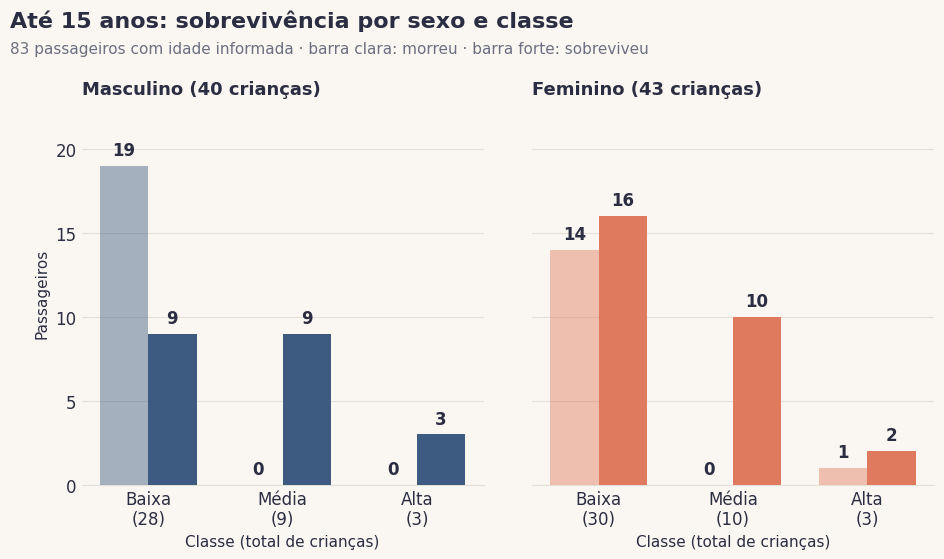

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

criancas = df[df['idade'] <= 15]

# Na sua coluna: 1 = baixa, 2 = média, 3 = alta (a inversão que você fez)
nomes_classe = {1: 'Baixa', 2: 'Média', 3: 'Alta'}

fig, axes = plt.subplots(1, 2, figsize=(11, 5.8), facecolor=FUNDO, sharey=True)

# Maior barra entre todos, para os dois gráficos ficarem na mesma escala
topo = criancas.groupby(['sexo', 'classe', 'sobreviveu']).size().max()
larg = 0.36

for ax, sexo in zip(axes, ['Masculino', 'Feminino']):
    ax.set_facecolor(FUNDO)

    g = criancas[criancas['sexo'] == sexo]

    # Tabela: linhas = classe, colunas = 0 (morreu) e 1 (sobreviveu)
    tab = pd.crosstab(g['classe'], g['sobreviveu'])
    tab = tab.reindex(index=[1, 2, 3], columns=[0, 1], fill_value=0)
    total_classe = tab.sum(axis=1)

    x = np.arange(3)

    # Uma barra clara (morreu) e uma forte (sobreviveu) por classe
    for j, (destino, transparencia) in enumerate([(0, 0.45), (1, 1.0)]):
        posicao = x + (j - 0.5) * larg
        ax.bar(posicao, tab[destino], larg, color=paleta_sexo[sexo],
               alpha=transparencia, zorder=3)

        for px, v, t in zip(posicao, tab[destino], total_classe):
            ax.text(px, v + 0.4, f'{v}', ha='center', va='bottom',
                    fontsize=12, fontweight='bold', color=TEXTO)

    ax.set_xticks(x)
    ax.set_xticklabels([f'{nomes_classe[c]}\n({total_classe[c]})' for c in [1, 2, 3]])
    ax.set_xlabel('Classe (total de crianças)', color=TEXTO, fontsize=11)

    ax.set_ylim(0, topo * 1.2)
    ax.yaxis.grid(True, color=GRADE, zorder=0)
    for lado in ['top', 'right', 'left']:
        ax.spines[lado].set_visible(False)
    ax.spines['bottom'].set_color(GRADE)
    ax.tick_params(colors=TEXTO, length=0, labelsize=12)
    ax.set_title(f'{sexo} ({tab.values.sum()} crianças)', loc='left',
                 color=TEXTO, fontsize=13, fontweight='bold')

axes[0].set_ylabel('Passageiros', color=TEXTO, fontsize=11)

fig.text(0.06, 0.95, 'Até 15 anos: sobrevivência por sexo e classe',
         fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.06, 0.905,
         f'{len(criancas)} passageiros com idade informada · barra clara: morreu · barra forte: sobreviveu',
         fontsize=11, color='#6B6F80', ha='left')

plt.subplots_adjust(top=0.82, wspace=0.12, bottom=0.16)
plt.show()

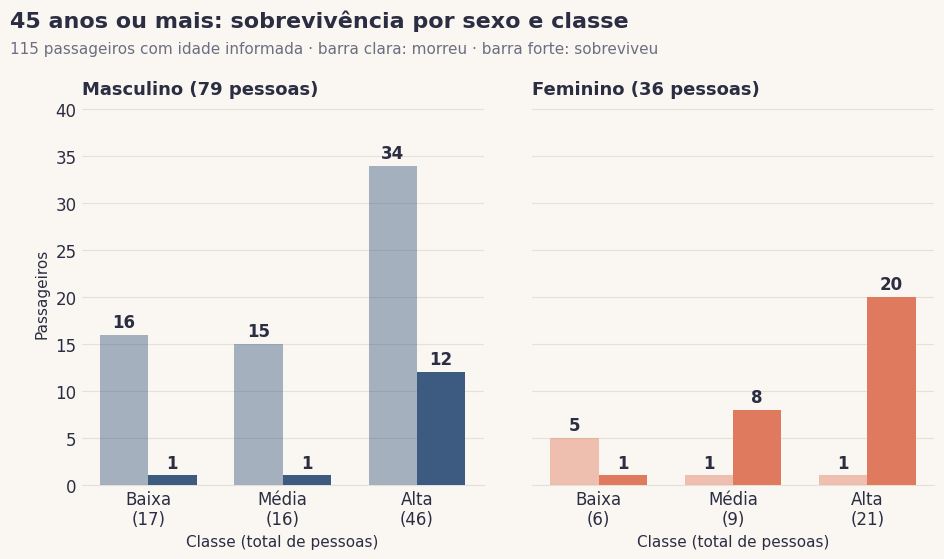

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def grafico_sexo_classe(filtro, titulo, rotulo_pessoas='pessoas'):
    """Sobrevivência por sexo e classe para o grupo definido em 'filtro'."""
    grupo = df[filtro]

    nomes_classe = {1: 'Baixa', 2: 'Média', 3: 'Alta'}   # sua inversão da classe
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.8), facecolor=FUNDO, sharey=True)

    topo = grupo.groupby(['sexo', 'classe', 'sobreviveu']).size().max()
    larg = 0.36

    for ax, sexo in zip(axes, ['Masculino', 'Feminino']):
        ax.set_facecolor(FUNDO)

        g = grupo[grupo['sexo'] == sexo]
        tab = pd.crosstab(g['classe'], g['sobreviveu'])
        tab = tab.reindex(index=[1, 2, 3], columns=[0, 1], fill_value=0)
        total_classe = tab.sum(axis=1)
        x = np.arange(3)

        for j, (destino, transparencia) in enumerate([(0, 0.45), (1, 1.0)]):
            posicao = x + (j - 0.5) * larg
            ax.bar(posicao, tab[destino], larg, color=paleta_sexo[sexo],
                   alpha=transparencia, zorder=3)
            for px, v in zip(posicao, tab[destino]):
                ax.text(px, v + 0.4, f'{v}', ha='center', va='bottom',
                        fontsize=12, fontweight='bold', color=TEXTO)

        ax.set_xticks(x)
        ax.set_xticklabels([f'{nomes_classe[c]}\n({total_classe[c]})' for c in [1, 2, 3]])
        ax.set_xlabel(f'Classe (total de {rotulo_pessoas})', color=TEXTO, fontsize=11)
        ax.set_ylim(0, topo * 1.2)
        ax.yaxis.grid(True, color=GRADE, zorder=0)
        for lado in ['top', 'right', 'left']:
            ax.spines[lado].set_visible(False)
        ax.spines['bottom'].set_color(GRADE)
        ax.tick_params(colors=TEXTO, length=0, labelsize=12)
        ax.set_title(f'{sexo} ({tab.values.sum()} {rotulo_pessoas})', loc='left',
                     color=TEXTO, fontsize=13, fontweight='bold')

    axes[0].set_ylabel('Passageiros', color=TEXTO, fontsize=11)
    fig.text(0.06, 0.95, titulo, fontsize=16, fontweight='bold', color=TEXTO, ha='left')
    fig.text(0.06, 0.905,
             f'{len(grupo)} passageiros com idade informada · barra clara: morreu · barra forte: sobreviveu',
             fontsize=11, color='#6B6F80', ha='left')
    plt.subplots_adjust(top=0.82, wspace=0.12, bottom=0.16)
    plt.show()


# Agora é só chamar com o recorte que quiser:
grafico_sexo_classe(df['idade'] >= 45, '45 anos ou mais: sobrevivência por sexo e classe')

### Local de embarque

O porto onde a pessoa embarcou tem relação com quem ela era? Olhamos o sexo e a sobrevivência por porto (Cherbourg, Queenstown e Southampton). Cuidado ao interpretar: o porto pode estar misturado com a classe, porque cada porto pode ter recebido um tipo diferente de passageiro.

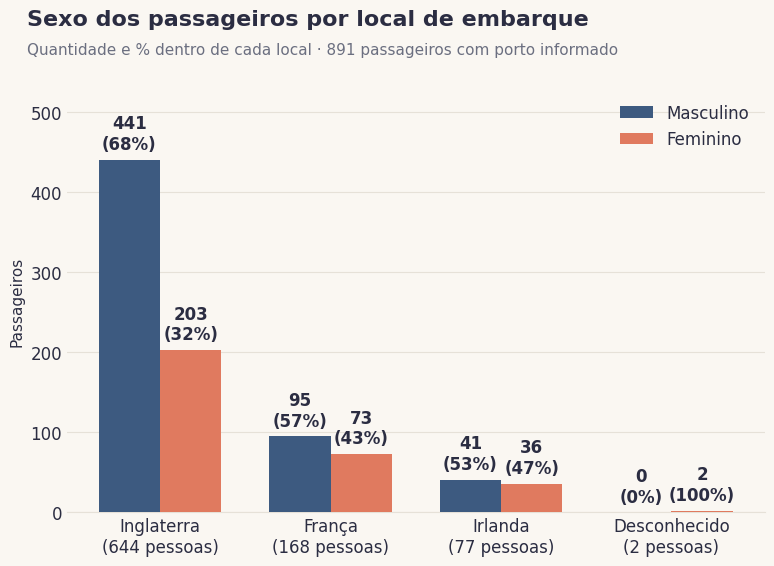

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Contagem de cada sexo em cada local de embarque
tab = pd.crosstab(df['pais_embarque'], df['sexo'])

# Ordena do local com mais passageiros para o com menos
ordem = tab.sum(axis=1).sort_values(ascending=False).index
tab = tab.loc[ordem, ['Masculino', 'Feminino']]
total_local = tab.sum(axis=1)

fig, ax = plt.subplots(figsize=(9, 5.8), facecolor=FUNDO)
ax.set_facecolor(FUNDO)

x = np.arange(len(tab))
larg = 0.36

for i, sexo in enumerate(['Masculino', 'Feminino']):
    posicao = x + (i - 0.5) * larg
    ax.bar(posicao, tab[sexo], larg, color=paleta_sexo[sexo], label=sexo, zorder=3)

    # número e percentual dentro de cada local
    for px, v, t in zip(posicao, tab[sexo], total_local):
        ax.text(px, v + 8, f'{v}\n({v/t:.0%})', ha='center', va='bottom',
                fontsize=12, fontweight='bold', color=TEXTO)

ax.set_xticks(x)
ax.set_xticklabels([f'{p}\n({total_local[p]} pessoas)' for p in tab.index])
ax.set_ylim(0, tab.values.max() * 1.2)
ax.yaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left']:
    ax.spines[lado].set_visible(False)
ax.spines['bottom'].set_color(GRADE)
ax.tick_params(colors=TEXTO, length=0, labelsize=12)
ax.set_ylabel('Passageiros', color=TEXTO, fontsize=11)
ax.legend(frameon=False, loc='upper right', fontsize=12, labelcolor=TEXTO)

fig.text(0.08, 0.95, 'Sexo dos passageiros por local de embarque',
         fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.08, 0.90,
         f'Quantidade e % dentro de cada local · {int(tab.values.sum())} passageiros com porto informado',
         fontsize=11, color='#6B6F80', ha='left')

plt.subplots_adjust(top=0.84)
plt.show()

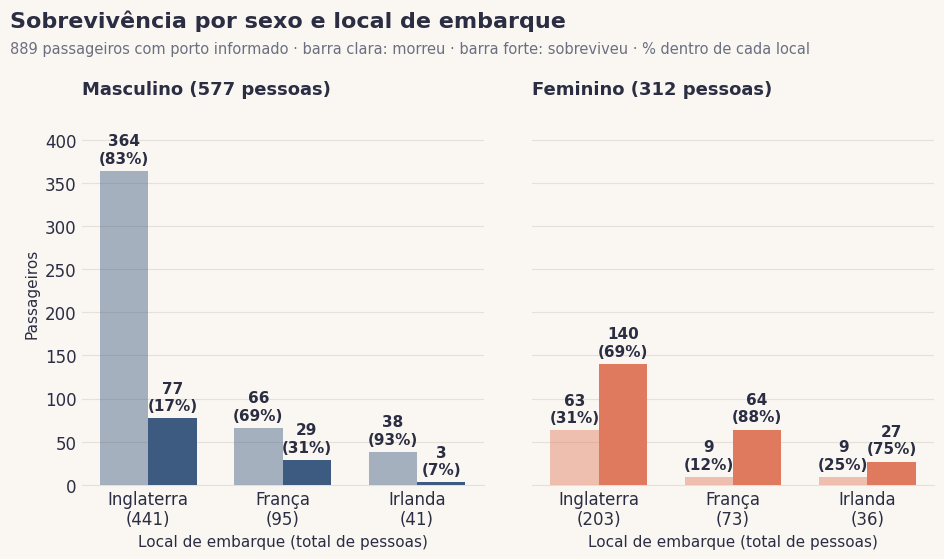

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Nomes que NÃO devem aparecer como local de embarque (se existirem na sua coluna)
ignorar = ['Desconhecido', 'Não informado', 'Sem informação']

# Só os locais de verdade, em ordem de tamanho (mais passageiros primeiro)
ordem = [p for p in df['pais_embarque'].value_counts().index if p not in ignorar]
grupo = df[df['pais_embarque'].isin(ordem)]

fig, axes = plt.subplots(1, 2, figsize=(11, 5.8), facecolor=FUNDO, sharey=True)

# Maior barra de todas, para os dois gráficos ficarem na mesma escala
topo = grupo.groupby(['sexo', 'pais_embarque', 'sobreviveu']).size().max()
larg = 0.36

for ax, sexo in zip(axes, ['Masculino', 'Feminino']):
    ax.set_facecolor(FUNDO)

    g = grupo[grupo['sexo'] == sexo]
    tab = pd.crosstab(g['pais_embarque'], g['sobreviveu'])
    tab = tab.reindex(index=ordem, columns=[0, 1], fill_value=0)
    total_local = tab.sum(axis=1)
    x = np.arange(len(ordem))

    # Uma barra clara (morreu) e uma forte (sobreviveu) por local
    for j, (destino, transparencia) in enumerate([(0, 0.45), (1, 1.0)]):
        posicao = x + (j - 0.5) * larg
        ax.bar(posicao, tab[destino], larg, color=paleta_sexo[sexo],
               alpha=transparencia, zorder=3)

        # Número e percentual dentro do local
        for px, v, t in zip(posicao, tab[destino], total_local):
            if t == 0:
                continue   # ninguém desse sexo nesse local: não escreve nada
            ax.text(px, v + 6, f'{v}\n({v/t:.0%})', ha='center', va='bottom',
                    fontsize=11, fontweight='bold', color=TEXTO)

    ax.set_xticks(x)
    ax.set_xticklabels([f'{p}\n({total_local[p]})' for p in ordem])
    ax.set_xlabel('Local de embarque (total de pessoas)', color=TEXTO, fontsize=11)
    ax.set_ylim(0, topo * 1.22)
    ax.yaxis.grid(True, color=GRADE, zorder=0)
    for lado in ['top', 'right', 'left']:
        ax.spines[lado].set_visible(False)
    ax.spines['bottom'].set_color(GRADE)
    ax.tick_params(colors=TEXTO, length=0, labelsize=12)
    ax.set_title(f'{sexo} ({tab.values.sum()} pessoas)', loc='left',
                 color=TEXTO, fontsize=13, fontweight='bold')

axes[0].set_ylabel('Passageiros', color=TEXTO, fontsize=11)

fig.text(0.06, 0.95, 'Sobrevivência por sexo e local de embarque',
         fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.06, 0.905,
         f'{len(grupo)} passageiros com porto informado · '
         'barra clara: morreu · barra forte: sobreviveu · % dentro de cada local',
         fontsize=10.5, color='#6B6F80', ha='left')

plt.subplots_adjust(top=0.82, wspace=0.12, bottom=0.16)
plt.show()

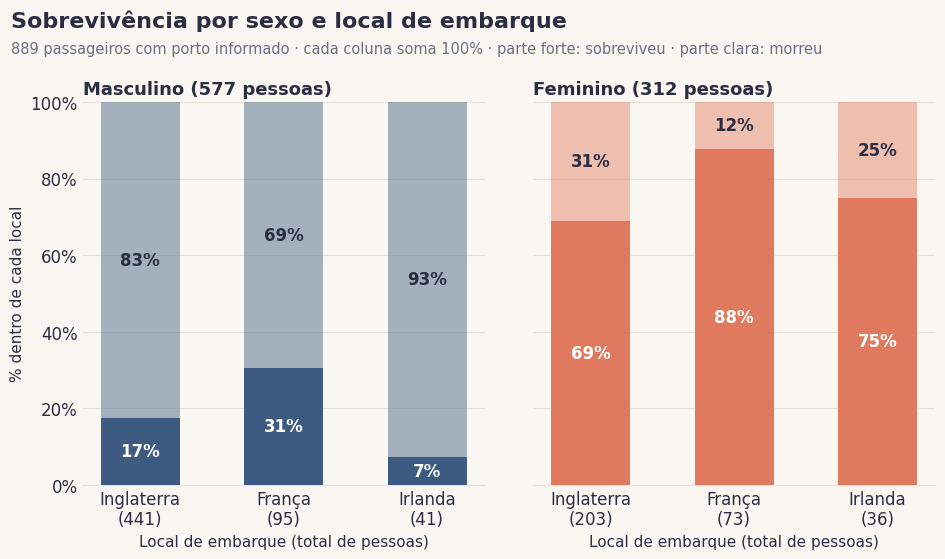

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Nomes que NÃO devem aparecer como local de embarque (se existirem na sua coluna)
ignorar = ['Desconhecido', 'Não informado', 'Sem informação']

# Só os locais de verdade, em ordem de tamanho
ordem = [p for p in df['pais_embarque'].value_counts().index if p not in ignorar]
grupo = df[df['pais_embarque'].isin(ordem)]

fig, axes = plt.subplots(1, 2, figsize=(11, 5.8), facecolor=FUNDO, sharey=True)
larg = 0.55

for ax, sexo in zip(axes, ['Masculino', 'Feminino']):
    ax.set_facecolor(FUNDO)

    g = grupo[grupo['sexo'] == sexo]
    tab = pd.crosstab(g['pais_embarque'], g['sobreviveu'])
    tab = tab.reindex(index=ordem, columns=[0, 1], fill_value=0)
    total_local = tab.sum(axis=1)

    # Normaliza: divide cada contagem pelo total do local (vira 0 a 1)
    pct = tab.div(total_local.replace(0, np.nan), axis=0).fillna(0)

    x = np.arange(len(ordem))

    # Embaixo: sobreviveu (forte). Em cima: morreu (claro)
    ax.bar(x, pct[1], larg, color=paleta_sexo[sexo], zorder=3)
    ax.bar(x, pct[0], larg, bottom=pct[1], color=paleta_sexo[sexo],
           alpha=0.45, zorder=3)

    # Percentual escrito dentro de cada pedaço
    for i, local in enumerate(ordem):
        if total_local[local] == 0:
            continue
        ax.text(i, pct[1][local] / 2, f'{pct[1][local]:.0%}', ha='center', va='center',
                fontsize=12, fontweight='bold', color='white')
        ax.text(i, pct[1][local] + pct[0][local] / 2, f'{pct[0][local]:.0%}',
                ha='center', va='center', fontsize=12, fontweight='bold', color=TEXTO)

    ax.set_xticks(x)
    ax.set_xticklabels([f'{p}\n({total_local[p]})' for p in ordem])
    ax.set_xlabel('Local de embarque (total de pessoas)', color=TEXTO, fontsize=11)
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.yaxis.grid(True, color=GRADE, zorder=0)
    for lado in ['top', 'right', 'left']:
        ax.spines[lado].set_visible(False)
    ax.spines['bottom'].set_color(GRADE)
    ax.tick_params(colors=TEXTO, length=0, labelsize=12)
    ax.set_title(f'{sexo} ({tab.values.sum()} pessoas)', loc='left',
                 color=TEXTO, fontsize=13, fontweight='bold')

axes[0].set_ylabel('% dentro de cada local', color=TEXTO, fontsize=11)

fig.text(0.06, 0.95, 'Sobrevivência por sexo e local de embarque',
         fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.06, 0.905,
         f'{len(grupo)} passageiros com porto informado · cada coluna soma 100% · '
         'parte forte: sobreviveu · parte clara: morreu',
         fontsize=10.5, color='#6B6F80', ha='left')

plt.subplots_adjust(top=0.82, wspace=0.12, bottom=0.16)
plt.show()

In [ ]:
df.head()

,id_passageiro,nome,titulo,titulo_pt,sobreviveu,sexo,idade,faixa_etaria,irmaos_conjuge,pais_filhos,classe,tarifa,tarifa_num,faixa_tarifa,cabine,cabine_letras,cabine_numeros,porto_embarque,pais_embarque
0,1,"Braund, Mr. Owen Harris",Mr,Senhor,0,Masculino,22.0,Jovem adulto (18 a 29 anos),1,0,1,7.25,7.250,"Tarifa baixa (0,00 – 7,91)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra
1,2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,Senhora,1,Feminino,38.0,Adulto (30 a 44 anos),1,0,3,712.833,712.833,"Tarifa alta (55,90 – 910,79)",C85,C,85,Cherbourg,França
2,3,"Heikkinen, Miss. Laina",Miss,Senhorita,1,Feminino,26.0,Jovem adulto (18 a 29 anos),0,0,1,7.925,7.925,"Tarifa média-baixa (7,91 – 15,50)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra
3,4,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,Senhora,1,Feminino,35.0,Adulto (30 a 44 anos),1,0,3,53.1,53.100,"Tarifa média-alta (15,50 – 55,90)",C123,C,123,Southampton,Inglaterra
4,5,"Allen, Mr. William Henry",Mr,Senhor,0,Masculino,35.0,Adulto (30 a 44 anos),0,0,1,8.05,8.050,"Tarifa média-baixa (7,91 – 15,50)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra


### Cabine

A maioria dos passageiros não tem cabine registrada. Olhamos a letra da cabine (o andar do navio) por classe e a sobrevivência por letra. Lembrete: quem tem cabine registrada é um grupo especial (em geral, de classes mais altas), então comparar com quem não tem cabine exige cuidado.

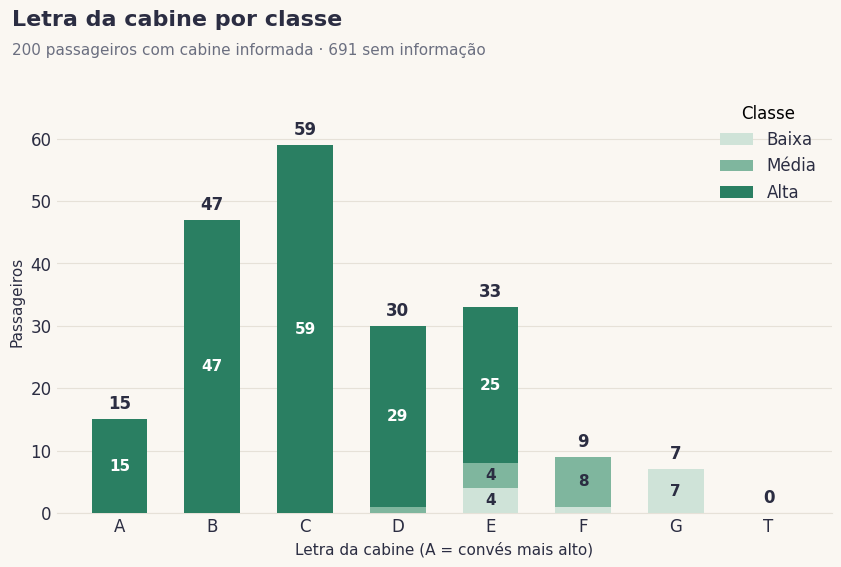

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Cores da classe: três tons da mesma cor, do mais claro (baixa) ao mais escuro (alta)
COR_CLASSE = {1: '#CFE3D8', 2: '#7FB69E', 3: '#2A7F62'}
nomes_classe = {1: 'Baixa', 2: 'Média', 3: 'Alta'}

decks = list('ABCDEFGT')

# Só vale se começar com uma letra de convés que NÃO seja o início de uma palavra
# ("D" e "D10" valem; "Desconhecido" não vale)
texto = df['cabine_letras'].astype(str).str.strip()
valida = texto.str.match(r'^[A-GT](?![a-z])')
grupo = df[valida].copy()
grupo['deck'] = texto[valida].str[0]

# Tabela: linhas = letra, colunas = classe
tab = pd.crosstab(grupo['deck'], grupo['classe'])
tab = tab.reindex(index=decks, columns=[1, 2, 3], fill_value=0)
total = tab.sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 5.8), facecolor=FUNDO)
ax.set_facecolor(FUNDO)

x = np.arange(len(decks))
base = np.zeros(len(decks))

for c in [1, 2, 3]:
    ax.bar(x, tab[c], 0.6, bottom=base, color=COR_CLASSE[c],
           label=nomes_classe[c], zorder=3)

    # Número dentro de cada pedaço (só se couber)
    for i, v in enumerate(tab[c]):
        if v >= 3:
            cor_texto = 'white' if c == 3 else TEXTO
            ax.text(i, base[i] + v / 2, str(v), ha='center', va='center',
                    fontsize=11, fontweight='bold', color=cor_texto)
    base += tab[c].values

# Total em cima de cada coluna
for i, t in enumerate(total):
    ax.text(i, t + 1, str(t), ha='center', va='bottom',
            fontsize=12, fontweight='bold', color=TEXTO)

ax.set_xticks(x)
ax.set_xticklabels(decks)
ax.set_xlabel('Letra da cabine (A = convés mais alto)', color=TEXTO, fontsize=11)
ax.set_ylabel('Passageiros', color=TEXTO, fontsize=11)
ax.set_ylim(0, total.max() * 1.15)
ax.yaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left']:
    ax.spines[lado].set_visible(False)
ax.spines['bottom'].set_color(GRADE)
ax.tick_params(colors=TEXTO, length=0, labelsize=12)
ax.legend(title='Classe', frameon=False, loc='upper right',
          fontsize=12, title_fontsize=12, labelcolor=TEXTO)

fig.text(0.08, 0.95, 'Letra da cabine por classe',
         fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.08, 0.90,
         f'{len(grupo)} passageiros com cabine informada · {len(df) - len(grupo)} sem informação',
         fontsize=11, color='#6B6F80', ha='left')

plt.subplots_adjust(top=0.84)
plt.show()

In [ ]:
df['cabine_letras'].value_counts()

,count
cabine_letras,
Desconhecido,691
C,59
B,47
E,33
D,30
A,15
F,9
G,7


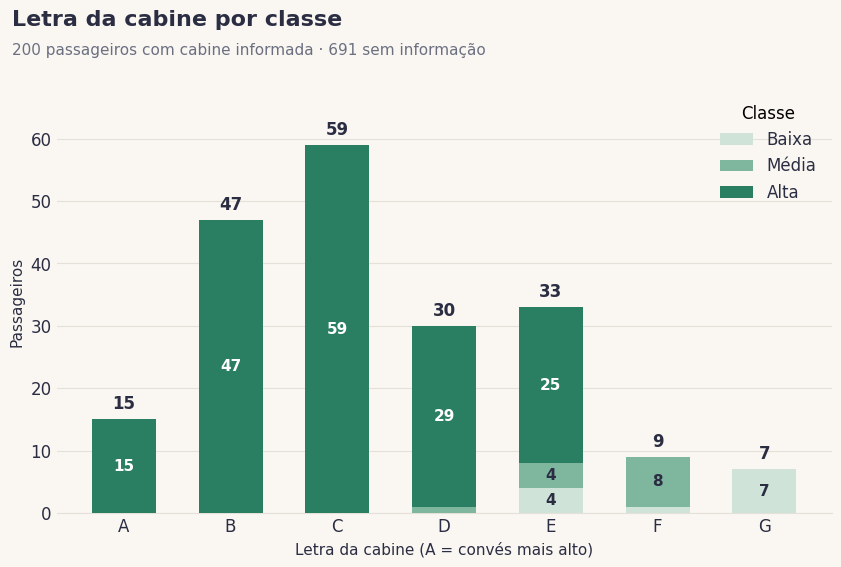

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Cores da classe: três tons da mesma cor, do mais claro (baixa) ao mais escuro (alta)
COR_CLASSE = {1: '#CFE3D8', 2: '#7FB69E', 3: '#2A7F62'}
nomes_classe = {1: 'Baixa', 2: 'Média', 3: 'Alta'}

# Tira o "Desconhecido" e fica só com as letras que existem
grupo = df[df['cabine_letras'] != 'Desconhecido']
decks = sorted(grupo['cabine_letras'].unique())

# Tabela: linhas = letra, colunas = classe
tab = pd.crosstab(grupo['cabine_letras'], grupo['classe'])
tab = tab.reindex(index=decks, columns=[1, 2, 3], fill_value=0)
total = tab.sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 5.8), facecolor=FUNDO)
ax.set_facecolor(FUNDO)

x = np.arange(len(decks))
base = np.zeros(len(decks))

for c in [1, 2, 3]:
    ax.bar(x, tab[c], 0.6, bottom=base, color=COR_CLASSE[c],
           label=nomes_classe[c], zorder=3)

    # Número dentro de cada pedaço (só se couber)
    for i, v in enumerate(tab[c]):
        if v >= 3:
            cor_texto = 'white' if c == 3 else TEXTO
            ax.text(i, base[i] + v / 2, str(v), ha='center', va='center',
                    fontsize=11, fontweight='bold', color=cor_texto)
    base += tab[c].values

# Total em cima de cada coluna
for i, t in enumerate(total):
    ax.text(i, t + 1, str(t), ha='center', va='bottom',
            fontsize=12, fontweight='bold', color=TEXTO)

ax.set_xticks(x)
ax.set_xticklabels(decks)
ax.set_xlabel('Letra da cabine (A = convés mais alto)', color=TEXTO, fontsize=11)
ax.set_ylabel('Passageiros', color=TEXTO, fontsize=11)
ax.set_ylim(0, total.max() * 1.15)
ax.yaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left']:
    ax.spines[lado].set_visible(False)
ax.spines['bottom'].set_color(GRADE)
ax.tick_params(colors=TEXTO, length=0, labelsize=12)
ax.legend(title='Classe', frameon=False, loc='upper right',
          fontsize=12, title_fontsize=12, labelcolor=TEXTO)

fig.text(0.08, 0.95, 'Letra da cabine por classe',
         fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.08, 0.90,
         f'{len(grupo)} passageiros com cabine informada · {len(df) - len(grupo)} sem informação',
         fontsize=11, color='#6B6F80', ha='left')

plt.subplots_adjust(top=0.84)
plt.show()

In [ ]:
df['classe'].value_counts()

,count
classe,
1,491
3,216
2,184


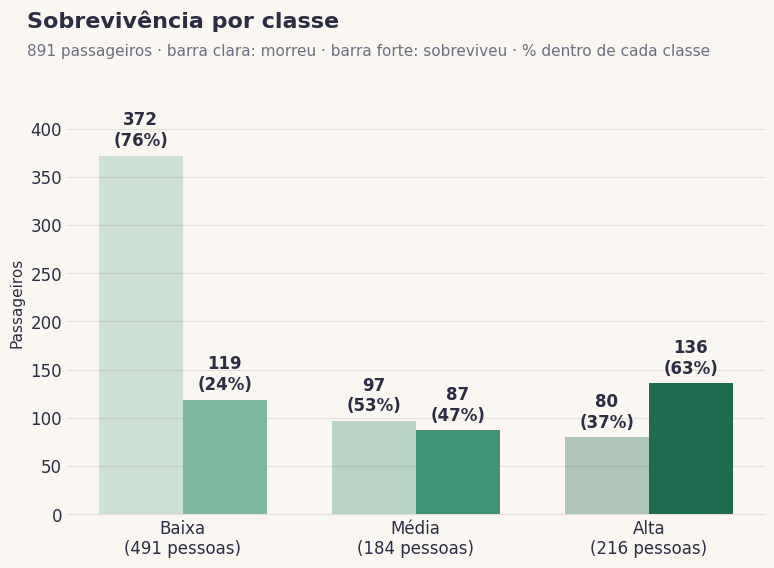

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Cores da classe: três tons da mesma cor, do mais claro (baixa) ao mais escuro (alta)
COR_CLASSE = {1: '#7DB89F', 2: '#3F9475', 3: '#1F6B50'}
nomes_classe = {1: 'Baixa', 2: 'Média', 3: 'Alta'}

# Tabela: linhas = classe, colunas = 0 (morreu) e 1 (sobreviveu)
tab = pd.crosstab(df['classe'], df['sobreviveu']).reindex(index=[1, 2, 3], columns=[0, 1])
total = tab.sum(axis=1)

fig, ax = plt.subplots(figsize=(9, 5.8), facecolor=FUNDO)
ax.set_facecolor(FUNDO)

x = np.arange(3)
larg = 0.36

for j, (destino, transparencia) in enumerate([(0, 0.35), (1, 1.0)]):
    posicao = x + (j - 0.5) * larg
    cores = [COR_CLASSE[c] for c in [1, 2, 3]]
    ax.bar(posicao, tab[destino], larg, color=cores, alpha=transparencia, zorder=3)
    for px, v, t in zip(posicao, tab[destino], total):
        ax.text(px, v + 6, f'{v}\n({v/t:.0%})', ha='center', va='bottom',
                fontsize=12, fontweight='bold', color=TEXTO)

ax.set_xticks(x)
ax.set_xticklabels([f'{nomes_classe[c]}\n({total[c]} pessoas)' for c in [1, 2, 3]])
ax.set_ylim(0, tab.values.max() * 1.18)
ax.yaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left']:
    ax.spines[lado].set_visible(False)
ax.spines['bottom'].set_color(GRADE)
ax.tick_params(colors=TEXTO, length=0, labelsize=12)
ax.set_ylabel('Passageiros', color=TEXTO, fontsize=11)

fig.text(0.08, 0.95, 'Sobrevivência por classe', fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.08, 0.90, f'{len(df)} passageiros · barra clara: morreu · barra forte: sobreviveu · % dentro de cada classe',
         fontsize=11, color='#6B6F80', ha='left')
plt.subplots_adjust(top=0.84)
plt.show()

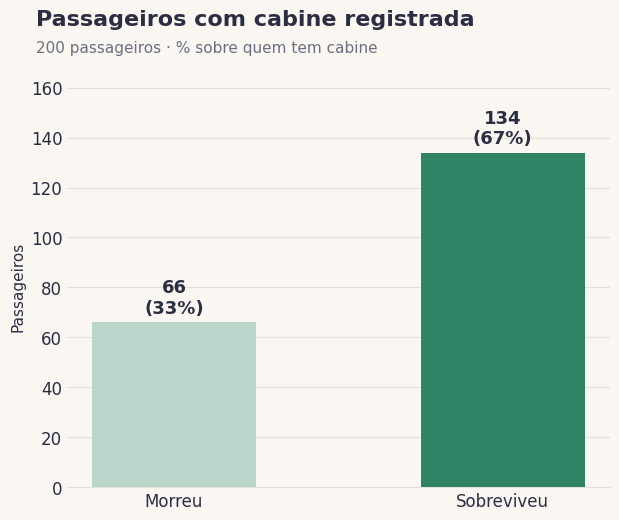

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Só quem tem cabine (tira o "Desconhecido")
com_cabine = df[df['cabine_letras'] != 'Desconhecido']

# Contagem: 0 = morreu, 1 = sobreviveu
cont = com_cabine['sobreviveu'].value_counts().reindex([0, 1])
total = cont.sum()

nomes = ['Morreu', 'Sobreviveu']
cores = ['#B9D8CB', '#2F8466']   # claro = morreu, forte = sobreviveu

fig, ax = plt.subplots(figsize=(7, 5.5), facecolor=FUNDO)
ax.set_facecolor(FUNDO)

barras = ax.bar(nomes, cont.values, width=0.5, color=cores, zorder=3)
for b, v in zip(barras, cont.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 2, f'{v}\n({v/total:.0%})',
            ha='center', va='bottom', fontsize=13, fontweight='bold', color=TEXTO)

ax.set_ylim(0, cont.max() * 1.2)
ax.yaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left']:
    ax.spines[lado].set_visible(False)
ax.spines['bottom'].set_color(GRADE)
ax.tick_params(colors=TEXTO, length=0, labelsize=12)
ax.set_ylabel('Passageiros', color=TEXTO, fontsize=11)

fig.text(0.08, 0.95, 'Passageiros com cabine registrada', fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.08, 0.90, f'{total} passageiros · % sobre quem tem cabine',
         fontsize=11, color='#6B6F80', ha='left')
plt.subplots_adjust(top=0.84)
plt.show()

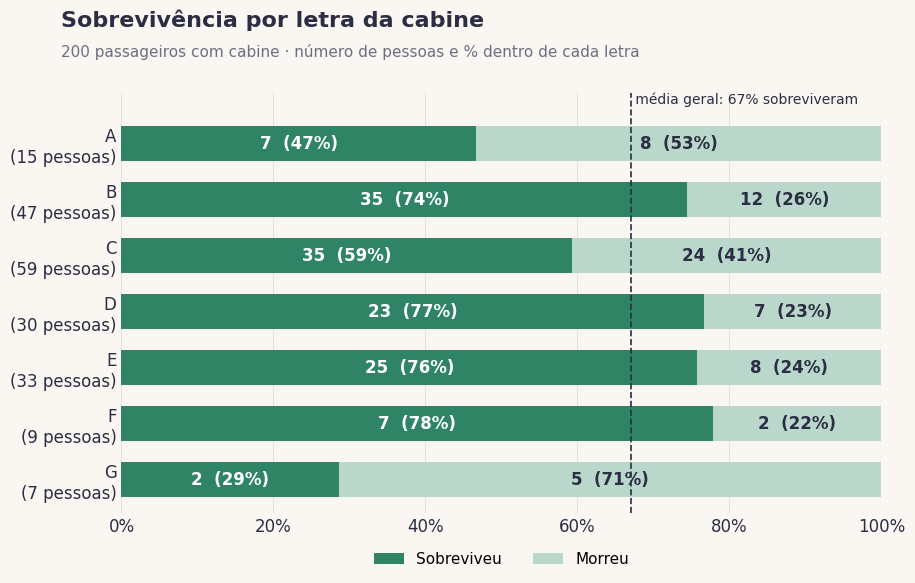

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Só quem tem cabine
com_cabine = df[df['cabine_letras'] != 'Desconhecido']

tab = pd.crosstab(com_cabine['cabine_letras'], com_cabine['sobreviveu']).reindex(columns=[0, 1], fill_value=0)
tab = tab.sort_index(ascending=False)       # invertido: a letra A fica no topo do gráfico
total = tab.sum(axis=1)
pct_sobrev = tab[1] / total
media_geral = tab[1].sum() / total.sum()    # % de sobrevivência de todo o grupo com cabine

COR_MORREU = '#B9D8CB'
COR_SOBREV = '#2F8466'

fig, ax = plt.subplots(figsize=(10, 6), facecolor=FUNDO)
ax.set_facecolor(FUNDO)

y = np.arange(len(tab))
ax.barh(y, pct_sobrev, height=0.62, color=COR_SOBREV, zorder=3, label='Sobreviveu')
ax.barh(y, 1 - pct_sobrev, left=pct_sobrev, height=0.62, color=COR_MORREU, zorder=3, label='Morreu')

# Textos dentro das barras: quantidade e porcentagem
for i, letra in enumerate(tab.index):
    s, m, t = tab.loc[letra, 1], tab.loc[letra, 0], total[letra]
    if s > 0:
        ax.text(pct_sobrev[letra] / 2, i, f'{s}  ({s/t:.0%})', ha='center', va='center',
                color='white', fontsize=12, fontweight='bold', zorder=4)
    if m > 0:
        ax.text(pct_sobrev[letra] + (1 - pct_sobrev[letra]) / 2, i, f'{m}  ({m/t:.0%})', ha='center', va='center',
                color=TEXTO, fontsize=12, fontweight='bold', zorder=4)

# Linha de referência: média de todo o grupo com cabine
ax.axvline(media_geral, color=TEXTO, linestyle='--', linewidth=1.2, zorder=5)
ax.text(media_geral, len(tab) - 0.35, f' média geral: {media_geral:.0%} sobreviveram',
        color=TEXTO, fontsize=10, ha='left', va='bottom')

ax.set_yticks(y)
ax.set_yticklabels([f'{l}\n({total[l]} pessoas)' for l in tab.index])
ax.set_xlim(0, 1)
ax.set_ylim(-0.6, len(tab) - 0.1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.xaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left', 'bottom']:
    ax.spines[lado].set_visible(False)
ax.tick_params(colors=TEXTO, length=0, labelsize=12)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=2, fontsize=11)

fig.text(0.08, 0.95, 'Sobrevivência por letra da cabine', fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.08, 0.90, f'{len(com_cabine)} passageiros com cabine · número de pessoas e % dentro de cada letra',
         fontsize=11, color='#6B6F80', ha='left')
plt.subplots_adjust(top=0.84, left=0.14, bottom=0.14)
plt.show()

### Faixa etária e crianças

Agora a sobrevivência por faixa etária e, de novo, as crianças de até 11 anos separadas por classe.

/tmp/ipykernel_21982/3274700978.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ordem = dados.groupby('faixa_etaria')['idade'].median().sort_values().index.tolist()


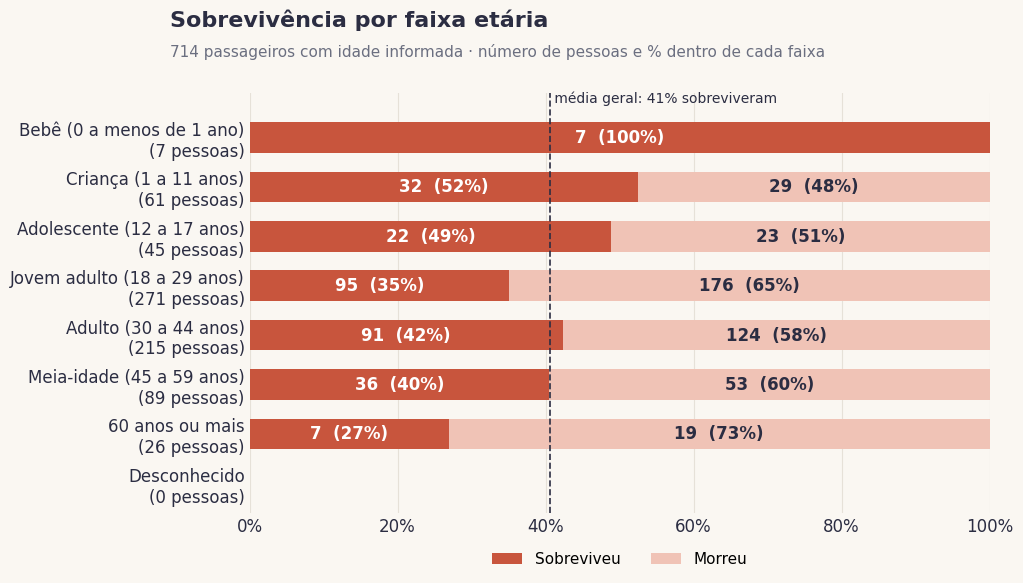

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Faixas que não são faixas de verdade (ajuste se o seu nome for diferente)
ignorar = ['Desconhecido', 'Não informado', 'Sem informação', 'Sem idade']
dados = df[~df['faixa_etaria'].isin(ignorar) & df['faixa_etaria'].notna()]

# Ordem automática: da faixa mais nova para a mais velha (pela idade mediana)
ordem = dados.groupby('faixa_etaria')['idade'].median().sort_values().index.tolist()

tab = pd.crosstab(dados['faixa_etaria'], dados['sobreviveu']).reindex(index=ordem, columns=[0, 1], fill_value=0)
tab = tab.iloc[::-1]                         # invertido: faixa mais nova no topo
total = tab.sum(axis=1)
pct_sobrev = tab[1] / total
media_geral = tab[1].sum() / total.sum()

COR_MORREU = '#F0C3B6'    # coral claro
COR_SOBREV = '#C8553D'    # coral forte
# (cores diferentes das outras variáveis: a idade ganha a sua própria cor)

fig, ax = plt.subplots(figsize=(10, 6), facecolor=FUNDO)
ax.set_facecolor(FUNDO)

y = np.arange(len(tab))
ax.barh(y, pct_sobrev, height=0.62, color=COR_SOBREV, zorder=3, label='Sobreviveu')
ax.barh(y, 1 - pct_sobrev, left=pct_sobrev, height=0.62, color=COR_MORREU, zorder=3, label='Morreu')

for i, faixa in enumerate(tab.index):
    s, m, t = tab.loc[faixa, 1], tab.loc[faixa, 0], total[faixa]
    if s > 0:
        ax.text(pct_sobrev[faixa] / 2, i, f'{s}  ({s/t:.0%})', ha='center', va='center',
                color='white', fontsize=12, fontweight='bold', zorder=4)
    if m > 0:
        ax.text(pct_sobrev[faixa] + (1 - pct_sobrev[faixa]) / 2, i, f'{m}  ({m/t:.0%})', ha='center', va='center',
                color=TEXTO, fontsize=12, fontweight='bold', zorder=4)

ax.axvline(media_geral, color=TEXTO, linestyle='--', linewidth=1.2, zorder=5)
ax.text(media_geral, len(tab) - 0.35, f' média geral: {media_geral:.0%} sobreviveram',
        color=TEXTO, fontsize=10, ha='left', va='bottom')

ax.set_yticks(y)
ax.set_yticklabels([f'{f}\n({total[f]} pessoas)' for f in tab.index])
ax.set_xlim(0, 1)
ax.set_ylim(-0.6, len(tab) - 0.1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.xaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left', 'bottom']:
    ax.spines[lado].set_visible(False)
ax.tick_params(colors=TEXTO, length=0, labelsize=12)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=2, fontsize=11)

fig.text(0.08, 0.95, 'Sobrevivência por faixa etária', fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.08, 0.90, f'{int(total.sum())} passageiros com idade informada · número de pessoas e % dentro de cada faixa',
         fontsize=11, color='#6B6F80', ha='left')
plt.subplots_adjust(top=0.84, left=0.16, bottom=0.14)
plt.show()

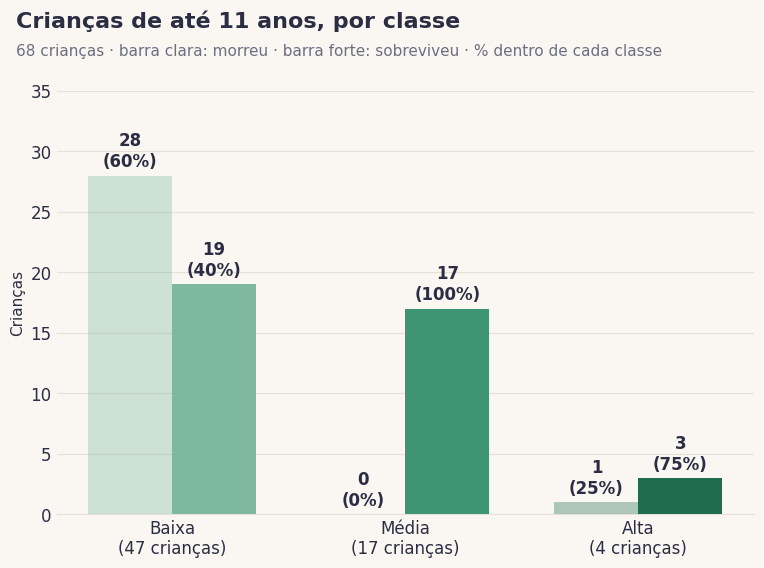

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Crianças com 11 anos ou menos (quem não tem idade fica de fora automaticamente)
criancas = df[df['idade'] <= 11]

COR_CLASSE = {1: '#7DB89F', 2: '#3F9475', 3: '#1F6B50'}
nomes_classe = {1: 'Baixa', 2: 'Média', 3: 'Alta'}

tab = pd.crosstab(criancas['classe'], criancas['sobreviveu']).reindex(index=[1, 2, 3], columns=[0, 1], fill_value=0)
total = tab.sum(axis=1)

fig, ax = plt.subplots(figsize=(9, 5.8), facecolor=FUNDO)
ax.set_facecolor(FUNDO)

x = np.arange(3)
larg = 0.36

for j, (destino, transparencia) in enumerate([(0, 0.35), (1, 1.0)]):
    posicao = x + (j - 0.5) * larg
    cores = [COR_CLASSE[c] for c in [1, 2, 3]]
    ax.bar(posicao, tab[destino], larg, color=cores, alpha=transparencia, zorder=3)
    for px, v, t in zip(posicao, tab[destino], total):
        if t == 0:
            continue
        ax.text(px, v + 0.4, f'{v}\n({v/t:.0%})', ha='center', va='bottom',
                fontsize=12, fontweight='bold', color=TEXTO)

ax.set_xticks(x)
ax.set_xticklabels([f'{nomes_classe[c]}\n({total[c]} crianças)' for c in [1, 2, 3]])
ax.set_ylim(0, tab.values.max() * 1.25)
ax.yaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left']:
    ax.spines[lado].set_visible(False)
ax.spines['bottom'].set_color(GRADE)
ax.tick_params(colors=TEXTO, length=0, labelsize=12)
ax.set_ylabel('Crianças', color=TEXTO, fontsize=11)

fig.text(0.08, 0.95, 'Crianças de até 11 anos, por classe', fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.08, 0.90, f'{len(criancas)} crianças · barra clara: morreu · barra forte: sobreviveu · % dentro de cada classe',
         fontsize=11, color='#6B6F80', ha='left')
plt.subplots_adjust(top=0.84)
plt.show()

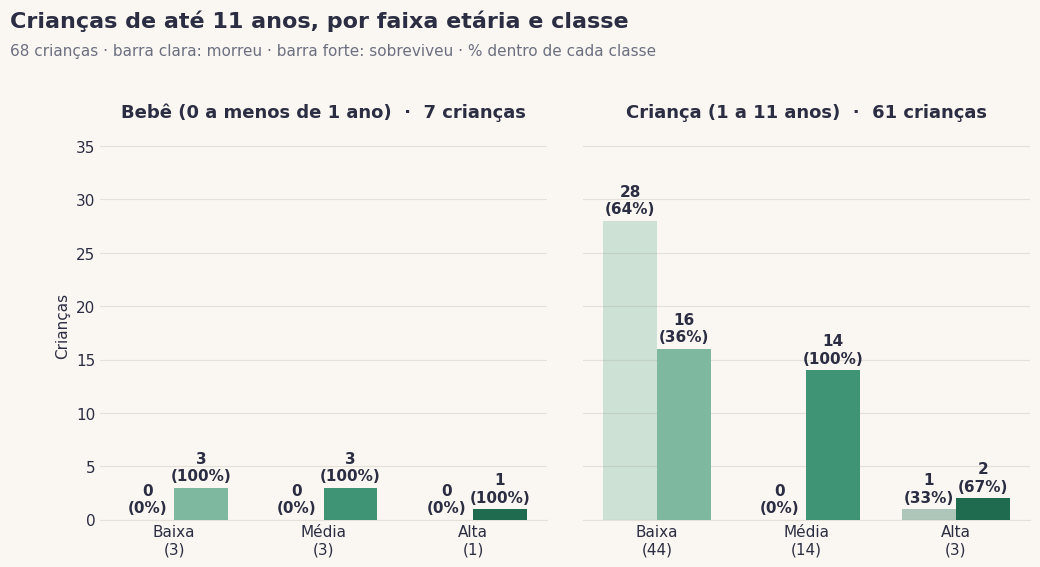

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# As duas faixas que queremos (nomes exatamente como estão na sua coluna)
faixas = ['Bebê (0 a menos de 1 ano)', 'Criança (1 a 11 anos)']

# Só quem está nessas duas faixas (já equivale a 11 anos ou menos)
criancas = df[df['faixa_etaria'].isin(faixas)]

COR_CLASSE = {1: '#7DB89F', 2: '#3F9475', 3: '#1F6B50'}
nomes_classe = {1: 'Baixa', 2: 'Média', 3: 'Alta'}

fig, axes = plt.subplots(1, len(faixas), figsize=(5.5 * len(faixas) + 1, 5.8),
                         sharey=True, facecolor=FUNDO, squeeze=False)
axes = axes[0]

# Mesma escala em todos os painéis
cont_max = (criancas.groupby(['faixa_etaria', 'classe', 'sobreviveu'], observed=True).size().max())

larg = 0.36
x = np.arange(3)

for ax, faixa in zip(axes, faixas):
    sub = criancas[criancas['faixa_etaria'] == faixa]
    tab = pd.crosstab(sub['classe'], sub['sobreviveu']).reindex(index=[1, 2, 3], columns=[0, 1], fill_value=0)
    total = tab.sum(axis=1)
    ax.set_facecolor(FUNDO)

    for j, (destino, transparencia) in enumerate([(0, 0.35), (1, 1.0)]):
        posicao = x + (j - 0.5) * larg
        ax.bar(posicao, tab[destino], larg, color=[COR_CLASSE[c] for c in [1, 2, 3]],
               alpha=transparencia, zorder=3)
        for px, v, t in zip(posicao, tab[destino], total):
            if t == 0:
                continue
            ax.text(px, v + 0.4, f'{v}\n({v/t:.0%})', ha='center', va='bottom',
                    fontsize=11, fontweight='bold', color=TEXTO)

    ax.set_title(f'{faixa}  ·  {len(sub)} crianças', fontsize=13, fontweight='bold', color=TEXTO, pad=10)
    ax.set_xticks(x)
    ax.set_xticklabels([f'{nomes_classe[c]}\n({total[c]})' for c in [1, 2, 3]])
    ax.set_ylim(0, cont_max * 1.3)
    ax.yaxis.grid(True, color=GRADE, zorder=0)
    for lado in ['top', 'right', 'left']:
        ax.spines[lado].set_visible(False)
    ax.spines['bottom'].set_color(GRADE)
    ax.tick_params(colors=TEXTO, length=0, labelsize=11)

axes[0].set_ylabel('Crianças', color=TEXTO, fontsize=11)

fig.text(0.05, 0.96, 'Crianças de até 11 anos, por faixa etária e classe', fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.05, 0.91, f'{len(criancas)} crianças · barra clara: morreu · barra forte: sobreviveu · % dentro de cada classe',
         fontsize=11, color='#6B6F80', ha='left')
plt.subplots_adjust(top=0.78, wspace=0.08)
plt.show()

### Correlação

O mapa de calor mostra o quanto cada par de colunas anda junto (de -1 a 1). Perto de zero, quase nenhuma relação; perto de 1 ou de -1, relação forte. Correlação mede **associação**, não causa: classe e tarifa andam juntas porque a tarifa faz parte do que define a classe.

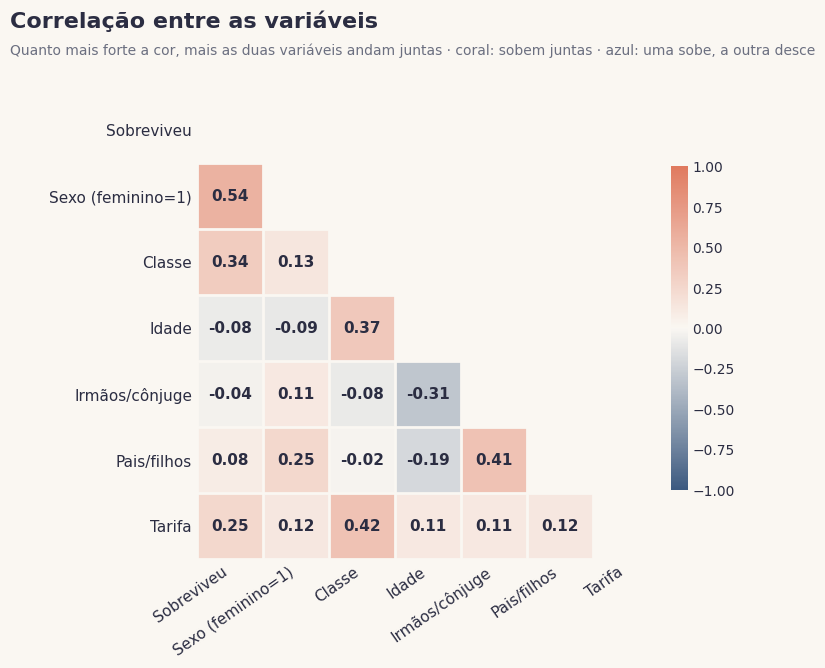

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# 1) Só colunas numéricas entram na correlação. O sexo é texto, então viramos número:
#    feminino = 1, masculino = 0
base = pd.DataFrame({
    'Sobreviveu':        df['sobreviveu'],
    'Sexo (feminino=1)': (df['sexo'] == 'Feminino').astype(int),
    'Classe':            df['classe'],
    'Idade':             df['idade'],
    'Irmãos/cônjuge':    df['irmaos_conjuge'],
    'Pais/filhos':       df['pais_filhos'],
    'Tarifa':            df['tarifa_num'],
})

# 2) Correlação (a idade vazia é ignorada só nos pares em que ela aparece)
corr = base.corr()

# 3) Paleta nossa: azul (negativa) -> creme (zero) -> coral (positiva)
cmap = LinearSegmentedColormap.from_list('titanic', [COR_MASC, FUNDO, COR_FEM])

# 4) Esconde o triângulo de cima (é espelho do de baixo)
mascara = np.triu(np.ones_like(corr, dtype=bool))
dados = np.ma.array(corr.values, mask=mascara)

fig, ax = plt.subplots(figsize=(9, 7), facecolor=FUNDO)
ax.set_facecolor(FUNDO)
im = ax.imshow(dados, cmap=cmap, vmin=-1, vmax=1)

nomes = corr.columns.tolist()
n = len(nomes)
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(nomes, rotation=35, ha='right', color=TEXTO, fontsize=11)
ax.set_yticklabels(nomes, color=TEXTO, fontsize=11)

# 5) Número dentro de cada quadradinho
for i in range(n):
    for j in range(n):
        if j < i:
            v = corr.iloc[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=11,
                    fontweight='bold', color='white' if abs(v) > 0.55 else TEXTO)

# Linhas entre os quadradinhos
ax.set_xticks(np.arange(-.5, n, 1), minor=True)
ax.set_yticks(np.arange(-.5, n, 1), minor=True)
ax.grid(which='minor', color=FUNDO, linewidth=2)
ax.tick_params(which='both', length=0)
for lado in ax.spines.values():
    lado.set_visible(False)

cbar = fig.colorbar(im, ax=ax, shrink=0.7, pad=0.02)
cbar.outline.set_visible(False)
cbar.ax.tick_params(colors=TEXTO, length=0)

fig.text(0.06, 0.96, 'Correlação entre as variáveis', fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.06, 0.92, 'Quanto mais forte a cor, mais as duas variáveis andam juntas · coral: sobem juntas · azul: uma sobe, a outra desce',
         fontsize=10, color='#6B6F80', ha='left')
plt.subplots_adjust(top=0.86, left=0.2, bottom=0.2)
plt.show()

In [ ]:
df.columns

Index(['id_passageiro', 'nome', 'titulo', 'titulo_pt', 'sobreviveu', 'sexo',
       'idade', 'faixa_etaria', 'irmaos_conjuge', 'pais_filhos', 'classe',
       'tarifa', 'tarifa_num', 'faixa_tarifa', 'cabine', 'cabine_letras',
       'cabine_numeros', 'porto_embarque', 'pais_embarque'],
      dtype='object')

### Olhando só as mulheres

Separamos as mulheres para ver o que diferencia quem sobreviveu de quem morreu: título, porto de embarque e classe. A pergunta que ficou: por que algumas mulheres das classes média e alta morreram?

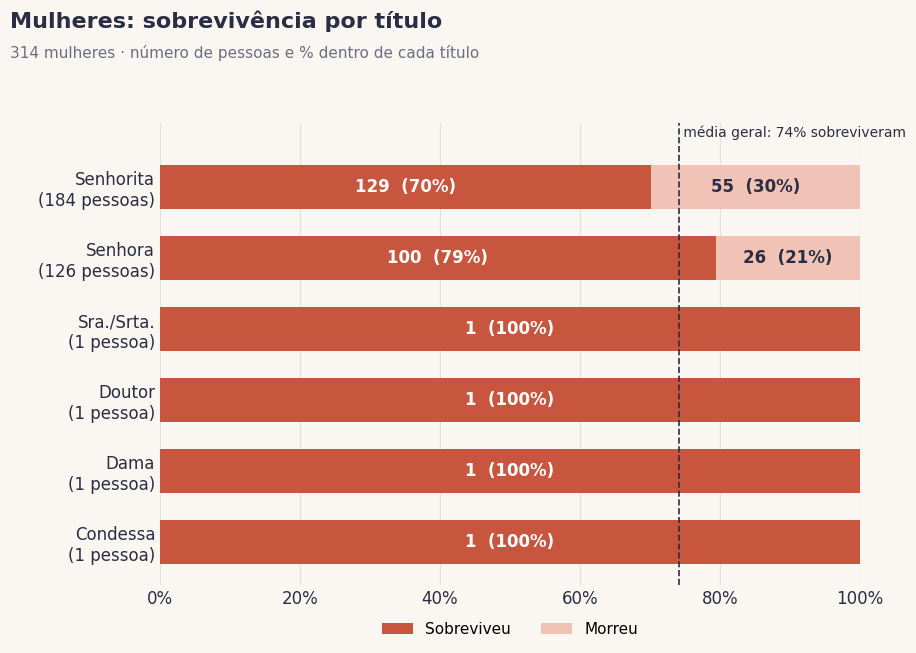

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Só as mulheres
mulheres = df[df['sexo'] == 'Feminino']

# Tabela: linhas = título em português, colunas = 0 (morreu) e 1 (sobreviveu)
tab = pd.crosstab(mulheres['titulo_pt'], mulheres['sobreviveu']).reindex(columns=[0, 1], fill_value=0)
tab = tab.loc[tab.sum(axis=1).sort_values().index]    # ordena do menor grupo (embaixo) ao maior (em cima)
total = tab.sum(axis=1)
pct_sobrev = tab[1] / total
media_geral = tab[1].sum() / total.sum()

COR_MORREU = '#F0C3B6'    # coral claro
COR_SOBREV = '#C8553D'    # coral forte

fig, ax = plt.subplots(figsize=(10, 0.7 * len(tab) + 2.6), facecolor=FUNDO)
ax.set_facecolor(FUNDO)

y = np.arange(len(tab))
ax.barh(y, pct_sobrev, height=0.62, color=COR_SOBREV, zorder=3, label='Sobreviveu')
ax.barh(y, 1 - pct_sobrev, left=pct_sobrev, height=0.62, color=COR_MORREU, zorder=3, label='Morreu')

for i, titulo in enumerate(tab.index):
    s, m, t = tab.loc[titulo, 1], tab.loc[titulo, 0], total[titulo]
    if s > 0:
        ax.text(pct_sobrev[titulo] / 2, i, f'{s}  ({s/t:.0%})', ha='center', va='center',
                color='white', fontsize=12, fontweight='bold', zorder=4)
    if m > 0:
        ax.text(pct_sobrev[titulo] + (1 - pct_sobrev[titulo]) / 2, i, f'{m}  ({m/t:.0%})', ha='center', va='center',
                color=TEXTO, fontsize=12, fontweight='bold', zorder=4)

ax.axvline(media_geral, color=TEXTO, linestyle='--', linewidth=1.2, zorder=5)
ax.text(media_geral, len(tab) - 0.35, f' média geral: {media_geral:.0%} sobreviveram',
        color=TEXTO, fontsize=10, ha='left', va='bottom')

ax.set_yticks(y)
ax.set_yticklabels([f"{t}\n({total[t]} {'pessoa' if total[t] == 1 else 'pessoas'})" for t in tab.index])
ax.set_xlim(0, 1)
ax.set_ylim(-0.6, len(tab) - 0.1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.xaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left', 'bottom']:
    ax.spines[lado].set_visible(False)
ax.tick_params(colors=TEXTO, length=0, labelsize=12)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=2, fontsize=11)

fig.text(0.05, 0.96, 'Mulheres: sobrevivência por título', fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.05, 0.915, f'{len(mulheres)} mulheres · número de pessoas e % dentro de cada título',
         fontsize=11, color='#6B6F80', ha='left')
plt.subplots_adjust(top=0.82, left=0.2, bottom=0.14)
plt.show()

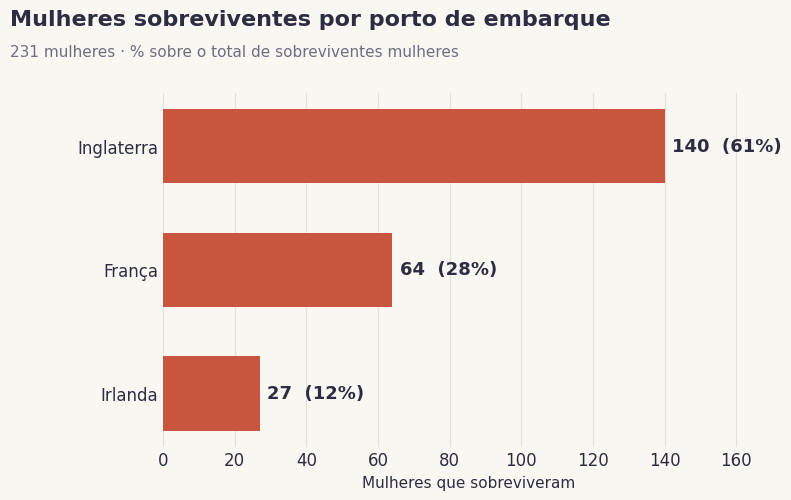

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Só as mulheres que sobreviveram
sobreviventes = df[(df['sexo'] == 'Feminino') & (df['sobreviveu'] == 1)]

# Tira quem não tem porto informado
ignorar = ['Desconhecido', 'Não informado', 'Sem informação']
sobreviventes = sobreviventes[~sobreviventes['pais_embarque'].isin(ignorar) & sobreviventes['pais_embarque'].notna()]

# Quantas saíram de cada porto (do maior para o menor)
cont = sobreviventes['pais_embarque'].value_counts()
total = cont.sum()

COR_SOBREV = '#C8553D'    # coral forte (mulher que sobreviveu)

fig, ax = plt.subplots(figsize=(9, 5.2), facecolor=FUNDO)
ax.set_facecolor(FUNDO)

y = np.arange(len(cont))[::-1]          # maior porto no topo
ax.barh(y, cont.values, height=0.6, color=COR_SOBREV, zorder=3)
for yi, v in zip(y, cont.values):
    ax.text(v + cont.max() * 0.015, yi, f'{v}  ({v/total:.0%})', ha='left', va='center',
            fontsize=13, fontweight='bold', color=TEXTO)

ax.set_yticks(y)
ax.set_yticklabels(cont.index)
ax.set_xlim(0, cont.max() * 1.22)
ax.xaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left', 'bottom']:
    ax.spines[lado].set_visible(False)
ax.tick_params(colors=TEXTO, length=0, labelsize=12)
ax.set_xlabel('Mulheres que sobreviveram', color=TEXTO, fontsize=11)

fig.text(0.05, 0.95, 'Mulheres sobreviventes por porto de embarque', fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.05, 0.89, f'{total} mulheres · % sobre o total de sobreviventes mulheres',
         fontsize=11, color='#6B6F80', ha='left')
plt.subplots_adjust(top=0.82, left=0.22, bottom=0.14)
plt.show()

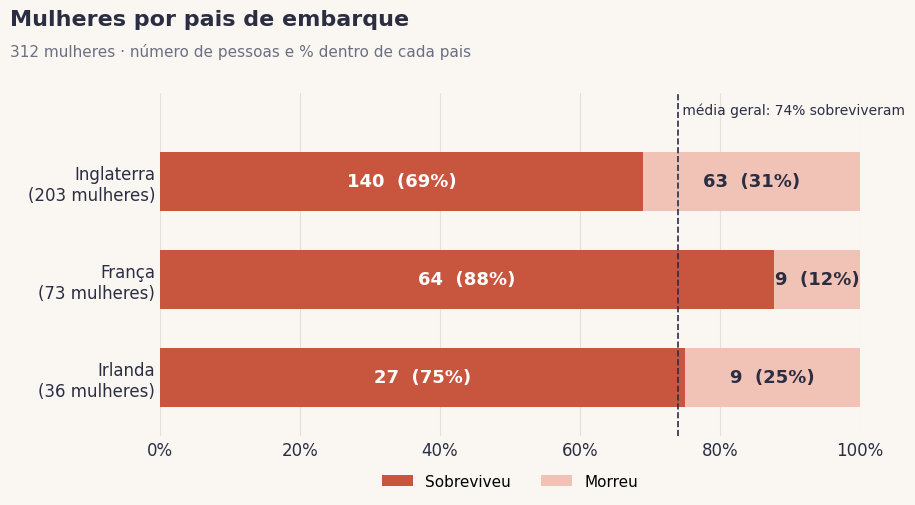

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Só as mulheres (as que sobreviveram E as que morreram)
mulheres = df[df['sexo'] == 'Feminino']

# Tira quem não tem pais informado
ignorar = ['Desconhecido', 'Não informado', 'Sem informação']
mulheres = mulheres[~mulheres['pais_embarque'].isin(ignorar) & mulheres['pais_embarque'].notna()]

# Tabela: linhas = pais, colunas = 0 (morreu) e 1 (sobreviveu)
tab = pd.crosstab(mulheres['pais_embarque'], mulheres['sobreviveu']).reindex(columns=[0, 1], fill_value=0)
tab = tab.loc[tab.sum(axis=1).sort_values().index]    # maior pais no topo
total = tab.sum(axis=1)
pct_sobrev = tab[1] / total
media_geral = tab[1].sum() / total.sum()

COR_MORREU = '#F0C3B6'    # coral claro
COR_SOBREV = '#C8553D'    # coral forte

fig, ax = plt.subplots(figsize=(10, 5.2), facecolor=FUNDO)
ax.set_facecolor(FUNDO)

y = np.arange(len(tab))
ax.barh(y, pct_sobrev, height=0.6, color=COR_SOBREV, zorder=3, label='Sobreviveu')
ax.barh(y, 1 - pct_sobrev, left=pct_sobrev, height=0.6, color=COR_MORREU, zorder=3, label='Morreu')

for i, pais in enumerate(tab.index):
    s, m, t = tab.loc[pais, 1], tab.loc[pais, 0], total[pais]
    if s > 0:
        ax.text(pct_sobrev[pais] / 2, i, f'{s}  ({s/t:.0%})', ha='center', va='center',
                color='white', fontsize=13, fontweight='bold', zorder=4)
    if m > 0:
        ax.text(pct_sobrev[pais] + (1 - pct_sobrev[pais]) / 2, i, f'{m}  ({m/t:.0%})', ha='center', va='center',
                color=TEXTO, fontsize=13, fontweight='bold', zorder=4)

ax.axvline(media_geral, color=TEXTO, linestyle='--', linewidth=1.2, zorder=5)
ax.text(media_geral, len(tab) - 0.35, f' média geral: {media_geral:.0%} sobreviveram',
        color=TEXTO, fontsize=10, ha='left', va='bottom')

ax.set_yticks(y)
ax.set_yticklabels([f"{p}\n({total[p]} mulheres)" for p in tab.index])
ax.set_xlim(0, 1)
ax.set_ylim(-0.6, len(tab) - 0.1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.xaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left', 'bottom']:
    ax.spines[lado].set_visible(False)
ax.tick_params(colors=TEXTO, length=0, labelsize=12)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.07), ncol=2, fontsize=11)

fig.text(0.05, 0.95, 'Mulheres por pais de embarque', fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.05, 0.89, f'{int(total.sum())} mulheres · número de pessoas e % dentro de cada pais',
         fontsize=11, color='#6B6F80', ha='left')
plt.subplots_adjust(top=0.82, left=0.2, bottom=0.16)
plt.show()

### Olhando só os homens

O mesmo exercício para os homens: sobrevivência por título e por classe (em números e em porcentagem dentro de cada classe).

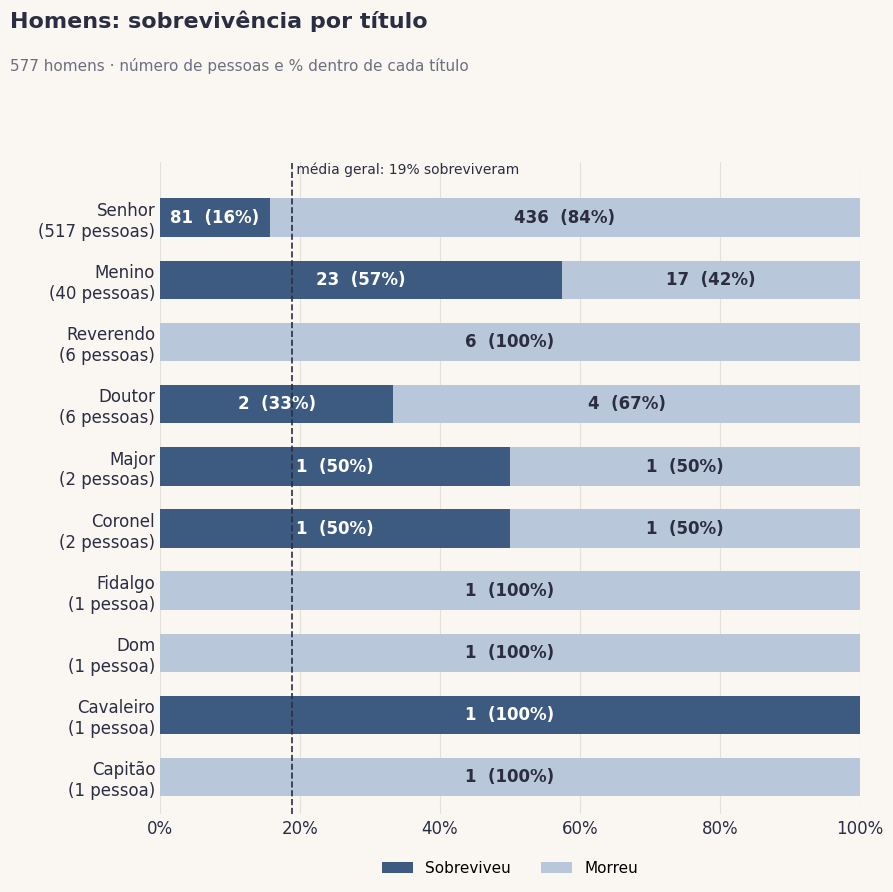

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Só os homens
homens = df[df['sexo'] == 'Masculino']

# Tabela: linhas = título em português, colunas = 0 (morreu) e 1 (sobreviveu)
tab = pd.crosstab(homens['titulo_pt'], homens['sobreviveu']).reindex(columns=[0, 1], fill_value=0)
tab = tab.loc[tab.sum(axis=1).sort_values().index]    # ordena do menor grupo (embaixo) ao maior (em cima)
total = tab.sum(axis=1)
pct_sobrev = tab[1] / total
media_geral = tab[1].sum() / total.sum()

COR_MORREU = '#B9C7DA'    # azul claro
COR_SOBREV = '#3D5A80'    # azul forte (nosso azul dos homens)

fig, ax = plt.subplots(figsize=(10, 0.7 * len(tab) + 2.6), facecolor=FUNDO)
ax.set_facecolor(FUNDO)

y = np.arange(len(tab))
ax.barh(y, pct_sobrev, height=0.62, color=COR_SOBREV, zorder=3, label='Sobreviveu')
ax.barh(y, 1 - pct_sobrev, left=pct_sobrev, height=0.62, color=COR_MORREU, zorder=3, label='Morreu')

for i, titulo in enumerate(tab.index):
    s, m, t = tab.loc[titulo, 1], tab.loc[titulo, 0], total[titulo]
    if s > 0:
        ax.text(pct_sobrev[titulo] / 2, i, f'{s}  ({s/t:.0%})', ha='center', va='center',
                color='white', fontsize=12, fontweight='bold', zorder=4)
    if m > 0:
        ax.text(pct_sobrev[titulo] + (1 - pct_sobrev[titulo]) / 2, i, f'{m}  ({m/t:.0%})', ha='center', va='center',
                color=TEXTO, fontsize=12, fontweight='bold', zorder=4)

ax.axvline(media_geral, color=TEXTO, linestyle='--', linewidth=1.2, zorder=5)
ax.text(media_geral, len(tab) - 0.35, f' média geral: {media_geral:.0%} sobreviveram',
        color=TEXTO, fontsize=10, ha='left', va='bottom')

ax.set_yticks(y)
ax.set_yticklabels([f"{t}\n({total[t]} {'pessoa' if total[t] == 1 else 'pessoas'})" for t in tab.index])
ax.set_xlim(0, 1)
ax.set_ylim(-0.6, len(tab) - 0.1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.xaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left', 'bottom']:
    ax.spines[lado].set_visible(False)
ax.tick_params(colors=TEXTO, length=0, labelsize=12)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=2, fontsize=11)

fig.text(0.05, 0.96, 'Homens: sobrevivência por título', fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.05, 0.915, f'{len(homens)} homens · número de pessoas e % dentro de cada título',
         fontsize=11, color='#6B6F80', ha='left')
plt.subplots_adjust(top=0.82, left=0.2, bottom=0.14)
plt.show()

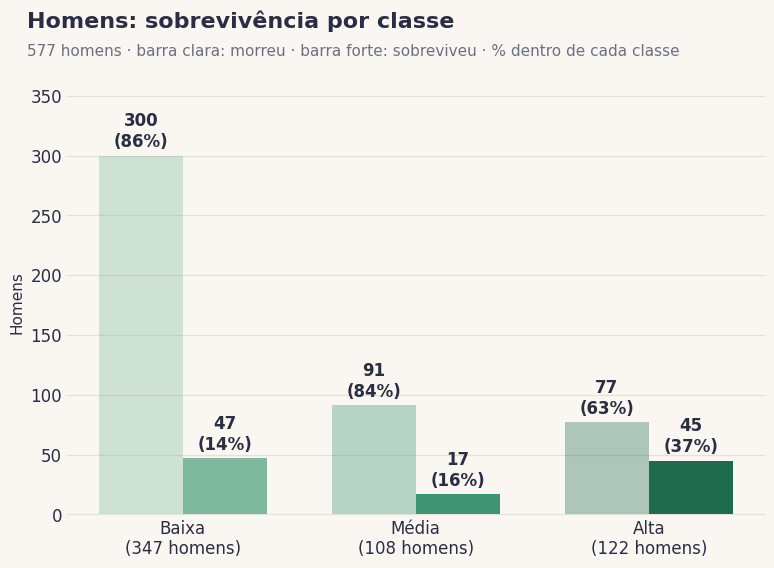

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Só os homens
homens = df[df['sexo'] == 'Masculino']

COR_CLASSE = {1: '#7DB89F', 2: '#3F9475', 3: '#1F6B50'}
nomes_classe = {1: 'Baixa', 2: 'Média', 3: 'Alta'}

tab = pd.crosstab(homens['classe'], homens['sobreviveu']).reindex(index=[1, 2, 3], columns=[0, 1], fill_value=0)
total = tab.sum(axis=1)

fig, ax = plt.subplots(figsize=(9, 5.8), facecolor=FUNDO)
ax.set_facecolor(FUNDO)

x = np.arange(3)
larg = 0.36

for j, (destino, transparencia) in enumerate([(0, 0.35), (1, 1.0)]):
    posicao = x + (j - 0.5) * larg
    cores = [COR_CLASSE[c] for c in [1, 2, 3]]
    ax.bar(posicao, tab[destino], larg, color=cores, alpha=transparencia, zorder=3)
    for px, v, t in zip(posicao, tab[destino], total):
        if t == 0:
            continue
        ax.text(px, v + 4, f'{v}\n({v/t:.0%})', ha='center', va='bottom',
                fontsize=12, fontweight='bold', color=TEXTO)

ax.set_xticks(x)
ax.set_xticklabels([f'{nomes_classe[c]}\n({total[c]} homens)' for c in [1, 2, 3]])
ax.set_ylim(0, tab.values.max() * 1.18)
ax.yaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left']:
    ax.spines[lado].set_visible(False)
ax.spines['bottom'].set_color(GRADE)
ax.tick_params(colors=TEXTO, length=0, labelsize=12)
ax.set_ylabel('Homens', color=TEXTO, fontsize=11)

fig.text(0.08, 0.95, 'Homens: sobrevivência por classe', fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.08, 0.90, f'{len(homens)} homens · barra clara: morreu · barra forte: sobreviveu · % dentro de cada classe',
         fontsize=11, color='#6B6F80', ha='left')
plt.subplots_adjust(top=0.84)
plt.show()

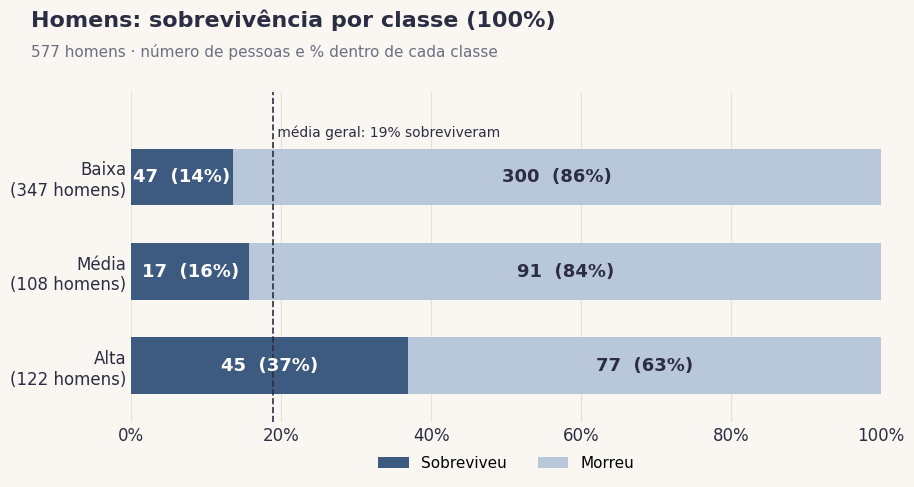

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Só os homens
homens = df[df['sexo'] == 'Masculino']

nomes_classe = {1: 'Baixa', 2: 'Média', 3: 'Alta'}

# Tabela: linhas = classe, colunas = 0 (morreu) e 1 (sobreviveu)
tab = pd.crosstab(homens['classe'], homens['sobreviveu']).reindex(index=[3, 2, 1], columns=[0, 1], fill_value=0)
total = tab.sum(axis=1)
pct_sobrev = tab[1] / total
media_geral = tab[1].sum() / total.sum()

COR_MORREU = '#B9C7DA'    # azul claro
COR_SOBREV = '#3D5A80'    # azul forte (nosso azul dos homens)

fig, ax = plt.subplots(figsize=(10, 5), facecolor=FUNDO)
ax.set_facecolor(FUNDO)

y = np.arange(3)
ax.barh(y, pct_sobrev, height=0.6, color=COR_SOBREV, zorder=3, label='Sobreviveu')
ax.barh(y, 1 - pct_sobrev, left=pct_sobrev, height=0.6, color=COR_MORREU, zorder=3, label='Morreu')

for i, c in enumerate([3, 2, 1]):
    s, m, t = tab.loc[c, 1], tab.loc[c, 0], total[c]
    ax.text(pct_sobrev[c] / 2, i, f'{s}  ({s/t:.0%})', ha='center', va='center',
            color='white', fontsize=13, fontweight='bold', zorder=4)
    ax.text(pct_sobrev[c] + (1 - pct_sobrev[c]) / 2, i, f'{m}  ({m/t:.0%})', ha='center', va='center',
            color=TEXTO, fontsize=13, fontweight='bold', zorder=4)

ax.axvline(media_geral, color=TEXTO, linestyle='--', linewidth=1.2, zorder=3.5)
ax.text(media_geral, 2.4, f' média geral: {media_geral:.0%} sobreviveram',
        color=TEXTO, fontsize=10, ha='left', va='bottom')

ax.set_yticks(y)
ax.set_yticklabels([f'{nomes_classe[c]}\n({total[c]} homens)' for c in [3, 2, 1]])
ax.set_xlim(0, 1)
ax.set_ylim(-0.6, 2.9)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.xaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left', 'bottom']:
    ax.spines[lado].set_visible(False)
ax.tick_params(colors=TEXTO, length=0, labelsize=12)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=2, fontsize=11)

fig.text(0.05, 0.95, 'Homens: sobrevivência por classe (100%)', fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.05, 0.89, f'{len(homens)} homens · número de pessoas e % dentro de cada classe',
         fontsize=11, color='#6B6F80', ha='left')
plt.subplots_adjust(top=0.82, left=0.15, bottom=0.16)
plt.show()

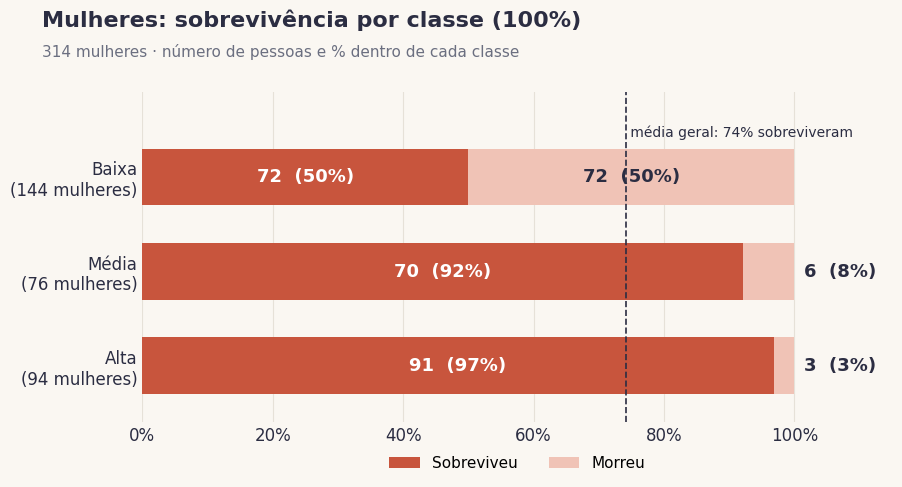

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Só as mulheres
mulheres = df[df['sexo'] == 'Feminino']

nomes_classe = {1: 'Baixa', 2: 'Média', 3: 'Alta'}

# Tabela: linhas = classe, colunas = 0 (morreu) e 1 (sobreviveu)
tab = pd.crosstab(mulheres['classe'], mulheres['sobreviveu']).reindex(index=[3, 2, 1], columns=[0, 1], fill_value=0)
total = tab.sum(axis=1)
pct_sobrev = tab[1] / total
media_geral = tab[1].sum() / total.sum()

COR_MORREU = '#F0C3B6'    # coral claro
COR_SOBREV = '#C8553D'    # coral forte (nosso coral das mulheres)

fig, ax = plt.subplots(figsize=(10, 5), facecolor=FUNDO)
ax.set_facecolor(FUNDO)

y = np.arange(3)
ax.barh(y, pct_sobrev, height=0.6, color=COR_SOBREV, zorder=3, label='Sobreviveu')
ax.barh(y, 1 - pct_sobrev, left=pct_sobrev, height=0.6, color=COR_MORREU, zorder=3, label='Morreu')

for i, c in enumerate([3, 2, 1]):
    s, m, t = tab.loc[c, 1], tab.loc[c, 0], total[c]
    ax.text(pct_sobrev[c] / 2, i, f'{s}  ({s/t:.0%})', ha='center', va='center',
            color='white', fontsize=13, fontweight='bold', zorder=4)
    if (1 - pct_sobrev[c]) < 0.15:      # fatia clara pequena: escreve o texto do lado de fora
        ax.text(1.015, i, f'{m}  ({m/t:.0%})', ha='left', va='center',
                color=TEXTO, fontsize=13, fontweight='bold', zorder=4)
    else:
        ax.text(pct_sobrev[c] + (1 - pct_sobrev[c]) / 2, i, f'{m}  ({m/t:.0%})', ha='center', va='center',
                color=TEXTO, fontsize=13, fontweight='bold', zorder=4)

ax.axvline(media_geral, color=TEXTO, linestyle='--', linewidth=1.2, zorder=3.5)
ax.text(media_geral, 2.4, f' média geral: {media_geral:.0%} sobreviveram',
        color=TEXTO, fontsize=10, ha='left', va='bottom')

ax.set_yticks(y)
ax.set_yticklabels([f'{nomes_classe[c]}\n({total[c]} mulheres)' for c in [3, 2, 1]])
ax.set_xlim(0, 1.15)
ax.set_ylim(-0.6, 2.9)
ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.xaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left', 'bottom']:
    ax.spines[lado].set_visible(False)
ax.tick_params(colors=TEXTO, length=0, labelsize=12)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=2, fontsize=11)

fig.text(0.05, 0.95, 'Mulheres: sobrevivência por classe (100%)', fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.05, 0.89, f'{len(mulheres)} mulheres · número de pessoas e % dentro de cada classe',
         fontsize=11, color='#6B6F80', ha='left')
plt.subplots_adjust(top=0.82, left=0.15, bottom=0.16)
plt.show()

In [ ]:
# Mulheres das classes média (2) e alta (3) que morreram
mortas = df[(df['sexo'] == 'Feminino') & (df['sobreviveu'] == 0) & (df['classe'].isin([2, 3]))]

colunas = ['id_passageiro', 'nome', 'titulo', 'titulo_pt', 'sobreviveu', 'sexo',
       'idade', 'faixa_etaria', 'irmaos_conjuge', 'pais_filhos', 'classe',
       'tarifa', 'tarifa_num', 'faixa_tarifa', 'cabine', 'cabine_letras',
       'cabine_numeros', 'porto_embarque', 'pais_embarque']
tabela = mortas[colunas].sort_values(['classe', 'idade'], ascending=[False, True])

print(len(tabela), 'mulheres')
tabela

9 mulheres


,id_passageiro,nome,titulo,titulo_pt,sobreviveu,sexo,idade,faixa_etaria,irmaos_conjuge,pais_filhos,classe,tarifa,tarifa_num,faixa_tarifa,cabine,cabine_letras,cabine_numeros,porto_embarque,pais_embarque
297,298,"Allison, Miss. Helen Loraine",Miss,Senhorita,0,Feminino,2.0,Criança (1 a 11 anos),1,2,3,151.55,151.550,"Tarifa alta (55,90 – 910,79)",C22 C26,C,22/26,Southampton,Inglaterra
498,499,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",Mrs,Senhora,0,Feminino,25.0,Jovem adulto (18 a 29 anos),1,2,3,151.55,151.550,"Tarifa alta (55,90 – 910,79)",C22 C26,C,22/26,Southampton,Inglaterra
177,178,"Isham, Miss. Ann Elizabeth",Miss,Senhorita,0,Feminino,50.0,Meia-idade (45 a 59 anos),0,0,3,287.125,287.125,"Tarifa alta (55,90 – 910,79)",C49,C,49,Cherbourg,França
199,200,"Yrois, Miss. Henriette (""Mrs Harbeck"")",Miss,Senhorita,0,Feminino,24.0,Jovem adulto (18 a 29 anos),0,0,2,13,13.000,"Tarifa média-baixa (7,91 – 15,50)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra
312,313,"Lahtinen, Mrs. William (Anna Sylfven)",Mrs,Senhora,0,Feminino,26.0,Jovem adulto (18 a 29 anos),1,1,2,26,26.000,"Tarifa média-alta (15,50 – 55,90)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra
41,42,"Turpin, Mrs. William John Robert (Dorothy Ann ...",Mrs,Senhora,0,Feminino,27.0,Jovem adulto (18 a 29 anos),1,0,2,21,21.000,"Tarifa média-alta (15,50 – 55,90)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra
357,358,"Funk, Miss. Annie Clemmer",Miss,Senhorita,0,Feminino,38.0,Adulto (30 a 44 anos),0,0,2,13,13.000,"Tarifa média-baixa (7,91 – 15,50)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra
854,855,"Carter, Mrs. Ernest Courtenay (Lilian Hughes)",Mrs,Senhora,0,Feminino,44.0,Adulto (30 a 44 anos),1,0,2,26,26.000,"Tarifa média-alta (15,50 – 55,90)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra
772,773,"Mack, Mrs. (Mary)",Mrs,Senhora,0,Feminino,57.0,Meia-idade (45 a 59 anos),0,0,2,10.5,10.500,"Tarifa média-baixa (7,91 – 15,50)",E77,E,77,Southampton,Inglaterra


In [ ]:
df.columns

Index(['id_passageiro', 'nome', 'titulo', 'titulo_pt', 'sobreviveu', 'sexo',
       'idade', 'faixa_etaria', 'irmaos_conjuge', 'pais_filhos', 'classe',
       'tarifa', 'tarifa_num', 'faixa_tarifa', 'cabine', 'cabine_letras',
       'cabine_numeros', 'porto_embarque', 'pais_embarque'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   id_passageiro   891 non-null    object  
 1   nome            891 non-null    object  
 2   titulo          891 non-null    object  
 3   titulo_pt       891 non-null    object  
 4   sobreviveu      891 non-null    int64   
 5   sexo            891 non-null    object  
 6   idade           714 non-null    float64 
 7   faixa_etaria    891 non-null    category
 8   irmaos_conjuge  891 non-null    int64   
 9   pais_filhos     891 non-null    int64   
 10  classe          891 non-null    int64   
 11  tarifa          891 non-null    object  
 12  tarifa_num      891 non-null    float64 
 13  faixa_tarifa    891 non-null    category
 14  cabine          891 non-null    object  
 15  cabine_letras   891 non-null    object  
 16  cabine_numeros  891 non-null    object  
 17  porto_embarque  

In [ ]:
df.head()

,id_passageiro,nome,titulo,titulo_pt,sobreviveu,sexo,idade,faixa_etaria,irmaos_conjuge,pais_filhos,classe,tarifa,tarifa_num,faixa_tarifa,cabine,cabine_letras,cabine_numeros,porto_embarque,pais_embarque
0,1,"Braund, Mr. Owen Harris",Mr,Senhor,0,Masculino,22.0,Jovem adulto (18 a 29 anos),1,0,1,7.25,7.250,"Tarifa baixa (0,00 – 7,91)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra
1,2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,Senhora,1,Feminino,38.0,Adulto (30 a 44 anos),1,0,3,712.833,712.833,"Tarifa alta (55,90 – 910,79)",C85,C,85,Cherbourg,França
2,3,"Heikkinen, Miss. Laina",Miss,Senhorita,1,Feminino,26.0,Jovem adulto (18 a 29 anos),0,0,1,7.925,7.925,"Tarifa média-baixa (7,91 – 15,50)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra
3,4,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,Senhora,1,Feminino,35.0,Adulto (30 a 44 anos),1,0,3,53.1,53.100,"Tarifa média-alta (15,50 – 55,90)",C123,C,123,Southampton,Inglaterra
4,5,"Allen, Mr. William Henry",Mr,Senhor,0,Masculino,35.0,Adulto (30 a 44 anos),0,0,1,8.05,8.050,"Tarifa média-baixa (7,91 – 15,50)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra


## 10. Os 177 passageiros sem idade

Cerca de 1 em cada 5 passageiros (177 de 891) não tem idade. Antes de preencher, perguntamos: **faltar idade é aleatório ou tem padrão?**

Fizemos um teste estatístico (qui-quadrado) em cada coluna. O padrão apareceu: quem está sem idade é mais frequente na classe baixa, no embarque em Queenstown (Irlanda), entre quem viaja sozinho e entre quem pagou tarifa baixa.

Isso importa: se faltasse idade ao acaso, bastaria preencher com a média. Como tem padrão, o preenchimento precisa respeitar esses grupos.

Sem idade: 177 de 891 (19.9%)

--- Classe  (p < 0,001) ---
  Alta: 13.9%  (30 de 216)
  Baixa: 27.7%  (136 de 491)
  Média: 6.0%  (11 de 184)

--- Sexo  (p = 0.119) ---
  Feminino: 16.9%  (53 de 314)
  Masculino: 21.5%  (124 de 577)

--- País de embarque  (p < 0,001) ---
  França: 22.6%  (38 de 168)
  Inglaterra: 14.0%  (90 de 644)
  Irlanda: 63.6%  (49 de 77)

--- Sobrevivência  (p = 0.008) ---
  Morreu: 22.8%  (125 de 549)
  Sobreviveu: 15.2%  (52 de 342)

--- Viaja com  (p < 0,001) ---
  Com família: 12.4%  (44 de 354)
  Sozinho(a): 24.8%  (133 de 537)

Tarifa mediana  -> com idade: 16.7 | sem idade: 8.05


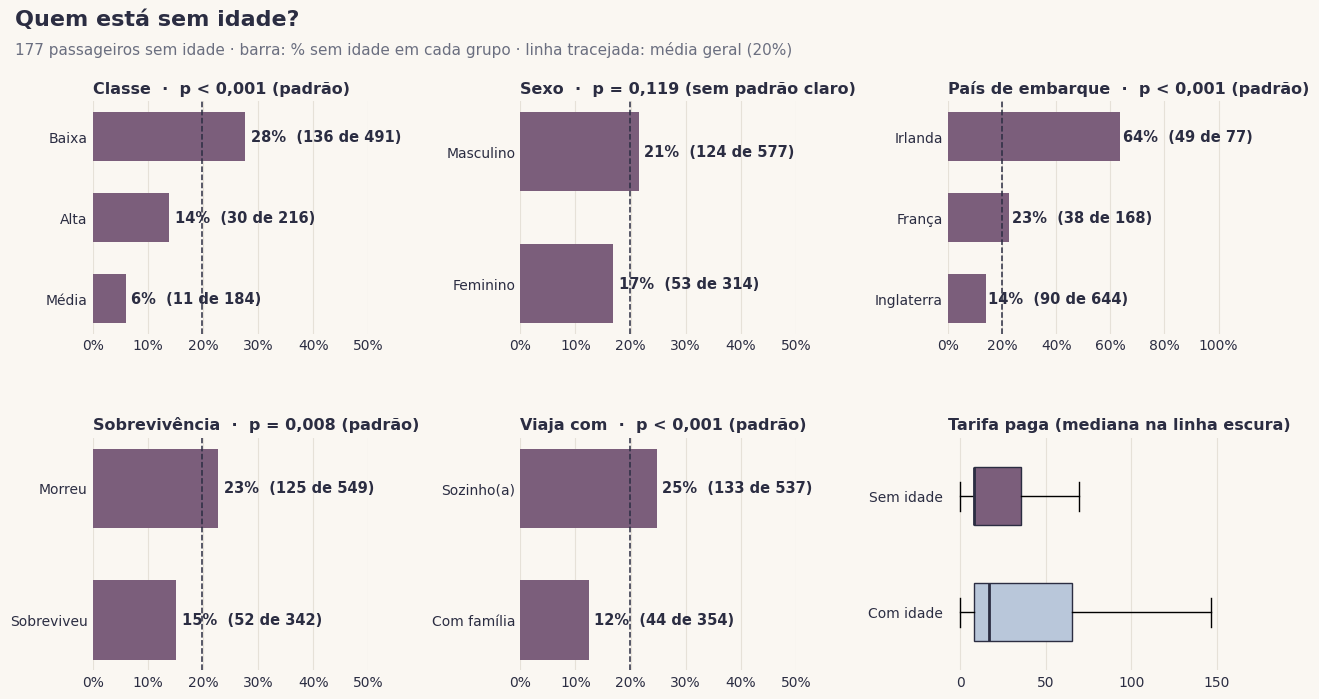

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from scipy.stats import chi2_contingency
warnings.filterwarnings('ignore', category=Warning)

# 1) Marca quem está sem idade
d = df.copy()
d['sem_idade'] = d['idade'].isna()
d['viaja'] = np.where(d['irmaos_conjuge'] + d['pais_filhos'] == 0, 'Sozinho(a)', 'Com família')
d['destino'] = d['sobreviveu'].map({0: 'Morreu', 1: 'Sobreviveu'})
d['classe_nome'] = d['classe'].map({1: 'Baixa', 2: 'Média', 3: 'Alta'})

media_geral = d['sem_idade'].mean()
print(f"Sem idade: {d['sem_idade'].sum()} de {len(d)} ({media_geral:.1%})\n")

# 2) Para cada coluna: % sem idade em cada categoria + teste qui-quadrado
#    (p-valor baixo, abaixo de 0,05, = a falta de idade NÃO é aleatória nessa coluna)
colunas = [('classe_nome', 'Classe'), ('sexo', 'Sexo'), ('pais_embarque', 'País de embarque'),
           ('destino', 'Sobrevivência'), ('viaja', 'Viaja com'), ]
resultados = {}
for col, nome in colunas:
    base = d[~d[col].isin(['Desconhecido', 'Não informado', 'Sem informação'])]   # ignora categorias vazias
    tab = pd.crosstab(base[col], base['sem_idade'])
    p = chi2_contingency(tab)[1]
    pct = base.groupby(col)['sem_idade'].agg(['mean', 'sum', 'count'])
    resultados[nome] = (pct, p)
    print(f'--- {nome}  ({"p < 0,001" if p < 0.001 else f"p = {p:.3f}"}) ---')
    for categoria, linha in pct.iterrows():
        print(f"  {categoria}: {linha['mean']:.1%}  ({int(linha['sum'])} de {int(linha['count'])})")
    print()

# 3) Tarifa: quem está sem idade paga mais ou menos?
print('Tarifa mediana  -> com idade:', d.loc[~d['sem_idade'], 'tarifa_num'].median(),
      '| sem idade:', d.loc[d['sem_idade'], 'tarifa_num'].median())

# 4) Gráfico: um painel por coluna, mostrando % sem idade em cada categoria
COR = '#7B5E7B'   # ameixa: cor própria para "sem idade"
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2), facecolor=FUNDO)
axes = axes.ravel()

for ax, (nome, (pct, p)) in zip(axes, resultados.items()):
    pct = pct.sort_values('mean')
    y = np.arange(len(pct))
    ax.set_facecolor(FUNDO)
    ax.barh(y, pct['mean'], height=0.6, color=COR, zorder=3)
    for yi, (m, n, t) in zip(y, pct[['mean', 'sum', 'count']].values):
        ax.text(m + 0.01, yi, f'{m:.0%}  ({int(n)} de {int(t)})', va='center', fontsize=10.5,
                fontweight='bold', color=TEXTO)
    ax.axvline(media_geral, color=TEXTO, linestyle='--', linewidth=1.1, zorder=4)
    ax.set_yticks(y)
    ax.set_yticklabels(pct.index, fontsize=11, color=TEXTO)
    ax.set_xlim(0, max(0.5, pct['mean'].max() * 1.6))
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
    ax.xaxis.grid(True, color=GRADE, zorder=0)
    for lado in ['top', 'right', 'left', 'bottom']:
        ax.spines[lado].set_visible(False)
    ax.tick_params(colors=TEXTO, length=0, labelsize=10)
    marca = 'padrão' if p < 0.05 else 'sem padrão claro'
    ptxt = 'p < 0,001' if p < 0.001 else f'p = {p:.3f}'.replace('.', ',')
    ax.set_title(f'{nome}  ·  {ptxt} ({marca})', fontsize=11.5, fontweight='bold', color=TEXTO, loc='left')

# último painel: tarifa (caixas)
ax = axes[5]
ax.set_facecolor(FUNDO)
dados = [d.loc[~d['sem_idade'], 'tarifa_num'].dropna(), d.loc[d['sem_idade'], 'tarifa_num'].dropna()]
bp = ax.boxplot(dados, vert=False, widths=0.5, patch_artist=True, showfliers=False,
                medianprops=dict(color=TEXTO, linewidth=2))
for caixa, cor in zip(bp['boxes'], ['#B9C7DA', COR]):
    caixa.set_facecolor(cor); caixa.set_edgecolor(TEXTO)
ax.set_yticklabels(['Com idade', 'Sem idade'], fontsize=11, color=TEXTO)
ax.xaxis.grid(True, color=GRADE, zorder=0)
for lado in ['top', 'right', 'left', 'bottom']:
    ax.spines[lado].set_visible(False)
ax.tick_params(colors=TEXTO, length=0, labelsize=10)
ax.set_title('Tarifa paga (mediana na linha escura)', fontsize=11.5, fontweight='bold', color=TEXTO, loc='left')

fig.text(0.04, 0.965, 'Quem está sem idade?', fontsize=16, fontweight='bold', color=TEXTO, ha='left')
fig.text(0.04, 0.925, f'{d["sem_idade"].sum()} passageiros sem idade · barra: % sem idade em cada grupo · linha tracejada: média geral ({media_geral:.0%})',
         fontsize=11, color='#6B6F80', ha='left')
plt.subplots_adjust(top=0.86, hspace=0.45, wspace=0.55, left=0.1, right=0.97, bottom=0.07)
plt.show()

## 11. Preenchendo a idade

Usamos a **mediana da idade por título e por classe**. Exemplo: um "Master" da classe baixa recebe a idade típica de um menino daquele grupo, e não a idade média do navio.

**Como saber se ficou bom?** Escondemos 20% das idades que conhecemos, deixamos o método adivinhar e comparamos com a idade real:

- Usar a média geral errava, em média, **11,3 anos**.
- Usar título + classe errou **9,1 anos**.

Melhorou, mas ainda é um chute. Por isso guardamos a coluna original `idade` para os gráficos de idade e criamos `idade_preenchida` só para o modelo. A coluna `idade_foi_preenchida` registra quem teve a idade completada.

In [ ]:
import numpy as np
import pandas as pd

MIN_GRUPO = 5   # só usa o grupo se tiver pelo menos 5 pessoas com idade conhecida

def preencher_idade(tabela):
    """Devolve a idade preenchida: mediana de título+classe; se o grupo for pequeno, só do título; senão, a geral."""
    idade = tabela['idade']
    com_idade = tabela[idade.notna()]

    # medianas e tamanhos dos grupos (calculados SÓ com quem tem idade)
    g_tc = com_idade.groupby(['titulo_pt', 'classe'])['idade'].agg(['median', 'count'])
    g_t = com_idade.groupby('titulo_pt')['idade'].agg(['median', 'count'])
    geral = com_idade['idade'].median()

    def escolher(linha):
        chave_tc = (linha['titulo_pt'], linha['classe'])
        if chave_tc in g_tc.index and g_tc.loc[chave_tc, 'count'] >= MIN_GRUPO:
            return g_tc.loc[chave_tc, 'median']
        if linha['titulo_pt'] in g_t.index and g_t.loc[linha['titulo_pt'], 'count'] >= MIN_GRUPO:
            return g_t.loc[linha['titulo_pt'], 'median']
        return geral

    chute = tabela.apply(escolher, axis=1)
    return idade.fillna(chute)

# 1) Cria as colunas novas (a coluna 'idade' original NÃO é alterada)
df['idade_foi_preenchida'] = df['idade'].isna()
df['idade_preenchida'] = preencher_idade(df)

# 2) Conferência
print('Sem idade antes :', df['idade'].isna().sum())
print('Sem idade depois:', df['idade_preenchida'].isna().sum())
print('\nMediana usada em cada grupo (quem teve a idade preenchida):')
print(df[df['idade_foi_preenchida']].groupby(['titulo_pt', 'classe'])['idade_preenchida']
        .agg(['median', 'count']).rename(columns={'median': 'idade_usada', 'count': 'pessoas'}))

# 3) Teste: esconde 20% das idades conhecidas e vê quanto o método erra
rng = np.random.default_rng(42)
conhecidas = df.index[df['idade'].notna()]
erros = {'média geral': [], 'mediana por título': [], 'mediana por título + classe': []}
for _ in range(200):                                   # repete 200 vezes pra ser confiável
    escondidos = rng.choice(conhecidas, size=int(len(conhecidas) * 0.2), replace=False)
    teste = df[['titulo_pt', 'classe', 'idade']].copy()
    verdade = teste.loc[escondidos, 'idade'].copy()
    teste.loc[escondidos, 'idade'] = np.nan
    resto = teste[teste['idade'].notna()]
    erros['média geral'].append((verdade - resto['idade'].mean()).abs().mean())
    med_t = resto.groupby('titulo_pt')['idade'].median()
    erros['mediana por título'].append((verdade - teste.loc[escondidos, 'titulo_pt'].map(med_t).fillna(resto['idade'].median())).abs().mean())
    teste['idade'] = preencher_idade(teste)
    erros['mediana por título + classe'].append((verdade - teste.loc[escondidos, 'idade']).abs().mean())

print('\nErro médio (em anos) ao tentar adivinhar idades que a gente conhece:')
for metodo, lista in erros.items():
    print(f'  {metodo:30s} {np.mean(lista):.1f} anos')

Sem idade antes : 177
Sem idade depois: 0

Mediana usada em cada grupo (quem teve a idade preenchida):
                  idade_usada  pessoas
titulo_pt classe                      
Doutor    3              46.5        1
Menino    1               4.0        4
Senhor    1              26.0       90
          2              31.0        9
          3              40.0       20
Senhora   1              31.0        9
          3              40.0        8
Senhorita 1              18.0       33
          2              24.0        2
          3              30.0        1

Erro médio (em anos) ao tentar adivinhar idades que a gente conhece:
  média geral                    11.3 anos
  mediana por título             9.5 anos
  mediana por título + classe    9.1 anos


In [ ]:
df.head()

,id_passageiro,nome,titulo,titulo_pt,sobreviveu,sexo,idade,faixa_etaria,irmaos_conjuge,pais_filhos,...,tarifa,tarifa_num,faixa_tarifa,cabine,cabine_letras,cabine_numeros,porto_embarque,pais_embarque,idade_foi_preenchida,idade_preenchida
0,1,"Braund, Mr. Owen Harris",Mr,Senhor,0,Masculino,22.0,Jovem adulto (18 a 29 anos),1,0,...,7.25,7.250,"Tarifa baixa (0,00 – 7,91)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra,False,22.0
1,2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,Senhora,1,Feminino,38.0,Adulto (30 a 44 anos),1,0,...,712.833,712.833,"Tarifa alta (55,90 – 910,79)",C85,C,85,Cherbourg,França,False,38.0
2,3,"Heikkinen, Miss. Laina",Miss,Senhorita,1,Feminino,26.0,Jovem adulto (18 a 29 anos),0,0,...,7.925,7.925,"Tarifa média-baixa (7,91 – 15,50)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra,False,26.0
3,4,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,Senhora,1,Feminino,35.0,Adulto (30 a 44 anos),1,0,...,53.1,53.100,"Tarifa média-alta (15,50 – 55,90)",C123,C,123,Southampton,Inglaterra,False,35.0
4,5,"Allen, Mr. William Henry",Mr,Senhor,0,Masculino,35.0,Adulto (30 a 44 anos),0,0,...,8.05,8.050,"Tarifa média-baixa (7,91 – 15,50)",Desconhecido,Desconhecido,Desconhecido,Southampton,Inglaterra,False,35.0


## 12. Conferindo e consertando a tarifa

Dois achados:

- **122 tarifas estavam erradas** (o ponto decimal foi lido no lugar errado e o valor ficou 10 vezes maior). Para corrigir, buscamos a tarifa no `train.csv` original do Kaggle, usando o `id_passageiro` como chave.
- **15 passageiros têm tarifa zero**. Todos homens, todos embarcaram em Southampton, e 14 dos 15 morreram. Não sabemos o motivo (talvez tripulação ou bilhetes de cortesia), então isso é uma hipótese, não um fato.

Depois do conserto, a tarifa mediana por classe ficou coerente: 8,05 na baixa, 15,02 na média e 61,98 na alta.

In [ ]:
import pandas as pd

# 1) Tem tarifa faltando (vazia)?
print('Tarifas vazias:', df['tarifa_num'].isna().sum())

# 2) Tem tarifa igual a zero?
zeros = df[df['tarifa_num'] == 0]
print('Tarifas iguais a zero:', len(zeros))

# 3) Quem são? (pra entender se é "dado faltando" ou se é real)
print('\nQuem tem tarifa zero:')
print(zeros[['id_passageiro', 'nome', 'sexo', 'classe', 'porto_embarque', 'sobreviveu']].to_string(index=False))

print('\nResumo desses', len(zeros), ':')
print('  Sexo   :', zeros['sexo'].value_counts().to_dict())
print('  Porto  :', zeros['porto_embarque'].value_counts().to_dict())
print('  Classe :', zeros['classe'].value_counts().sort_index().to_dict())
print('  Sobreviveram:', int(zeros['sobreviveu'].sum()), 'de', len(zeros))

# 4) Para comparar: a tarifa mediana de cada classe (sem os zeros)
print('\nTarifa mediana por classe (sem os zeros):')
print(df[df['tarifa_num'] > 0].groupby('classe')['tarifa_num'].median().round(2))

Tarifas vazias: 0
Tarifas iguais a zero: 15

Quem tem tarifa zero:
id_passageiro                             nome      sexo  classe porto_embarque  sobreviveu
          180              Leonard, Mr. Lionel Masculino       1    Southampton           0
          264            Harrison, Mr. William Masculino       3    Southampton           0
          272     Tornquist, Mr. William Henry Masculino       1    Southampton           1
          278      Parkes, Mr. Francis "Frank" Masculino       2    Southampton           0
          303  Johnson, Mr. William Cahoone Jr Masculino       1    Southampton           0
          414   Cunningham, Mr. Alfred Fleming Masculino       2    Southampton           0
          467            Campbell, Mr. William Masculino       2    Southampton           0
          482 Frost, Mr. Anthony Wood "Archie" Masculino       2    Southampton           0
          598              Johnson, Mr. Alfred Masculino       1    Southampton           0
          634

In [ ]:
import pandas as pd

original = pd.read_csv('train.csv')[['PassengerId', 'Fare']]

base = df[['id_passageiro', 'nome', 'classe', 'tarifa', 'tarifa_num']].copy()
base['id_passageiro'] = pd.to_numeric(base['id_passageiro'], errors='coerce')   # texto -> número
print('Ids que não viraram número:', base['id_passageiro'].isna().sum())

comp = base.merge(original, left_on='id_passageiro', right_on='PassengerId')

# Linhas em que a sua tarifa_num é diferente da tarifa original
dif = comp[(comp['tarifa_num'] - comp['Fare']).abs() > 0.01]

print('Linhas juntadas:', len(comp), 'de', len(base))
print('Linhas diferentes:', len(dif))
print(dif.groupby('classe').size())
dif.head(15)

Ids que não viraram número: 0
Linhas juntadas: 891 de 891
Linhas diferentes: 122
classe
1    53
2    12
3    57
dtype: int64


,id_passageiro,nome,classe,tarifa,tarifa_num,PassengerId,Fare
1,2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",3,712.833,712.833,2,71.2833
6,7,"McCarthy, Mr. Timothy J",3,518.625,518.625,7,51.8625
9,10,"Nasser, Mrs. Nicholas (Adele Achem)",2,300.708,300.708,10,30.0708
25,26,"Asplund, Mrs. Carl Oscar (Selma Augusta Emilia...",1,313.875,313.875,26,31.3875
30,31,"Uruchurtu, Don. Manuel E",3,277.208,277.208,31,27.7208
34,35,"Meyer, Mr. Edgar Joseph",3,821.708,821.708,35,82.1708
43,44,"Laroche, Miss. Simonne Marie Anne Andree",2,415.792,415.792,44,41.5792
48,49,"Samaan, Mr. Youssef",1,216.792,216.792,49,21.6792
50,51,"Panula, Master. Juha Niilo",1,396.875,396.875,51,39.6875
52,53,"Harper, Mrs. Henry Sleeper (Myna Haxtun)",3,767.292,767.292,53,76.7292


In [ ]:
import pandas as pd

original = pd.read_csv('train.csv')
tarifa_certa = original.set_index('PassengerId')['Fare']

ids = pd.to_numeric(df['id_passageiro'])            # id como número
df['tarifa_num'] = ids.map(tarifa_certa)            # tarifa correta, buscada pelo id
df['tarifa'] = df['tarifa_num']                     # a coluna 'tarifa' fica igual

# Conferência
print('Tarifas vazias:', df['tarifa_num'].isna().sum())
print('Diferença máxima para o original:', (df['tarifa_num'] - ids.map(tarifa_certa)).abs().max())
print('\nTarifa mediana por classe (sem os zeros):')
print(df[df['tarifa_num'] > 0].groupby('classe')['tarifa_num'].median().round(2))

Tarifas vazias: 0
Diferença máxima para o original: 0.0

Tarifa mediana por classe (sem os zeros):
classe
1     8.05
2    15.02
3    61.98
Name: tarifa_num, dtype: float64


In [ ]:
df.columns

Index(['id_passageiro', 'nome', 'titulo', 'titulo_pt', 'sobreviveu', 'sexo',
       'idade', 'faixa_etaria', 'irmaos_conjuge', 'pais_filhos', 'classe',
       'tarifa', 'tarifa_num', 'faixa_tarifa', 'cabine', 'cabine_letras',
       'cabine_numeros', 'porto_embarque', 'pais_embarque',
       'idade_foi_preenchida', 'idade_preenchida'],
      dtype='object')

## 13. Colunas novas para ajudar o modelo

- `tarifa_zero`: marca quem pagou 0.
- `pessoas_no_bilhete`: quantas pessoas dividiam o mesmo bilhete.
- `tarifa_por_pessoa`: a tarifa dividida pelas pessoas do bilhete. A tarifa do Titanic é o valor **total** do bilhete, repetido para cada passageiro dele, então essa divisão mostra o que cada um pagou de fato.

In [ ]:
import numpy as np
import pandas as pd

# =====================================================================
# PARTE A — IDADE  (a coluna 'idade' original não é alterada)
# =====================================================================
MIN_GRUPO = 5

def preencher_idade(tabela):
    """Mediana de título+classe; se o grupo tiver menos de 5 pessoas, só do título; senão, a geral."""
    idade = tabela['idade']
    com_idade = tabela[idade.notna()]
    g_tc = com_idade.groupby(['titulo_pt', 'classe'])['idade'].agg(['median', 'count'])
    g_t = com_idade.groupby('titulo_pt')['idade'].agg(['median', 'count'])
    geral = com_idade['idade'].median()

    def escolher(linha):
        chave = (linha['titulo_pt'], linha['classe'])
        if chave in g_tc.index and g_tc.loc[chave, 'count'] >= MIN_GRUPO:
            return g_tc.loc[chave, 'median']
        if linha['titulo_pt'] in g_t.index and g_t.loc[linha['titulo_pt'], 'count'] >= MIN_GRUPO:
            return g_t.loc[linha['titulo_pt'], 'median']
        return geral
    return idade.fillna(tabela.apply(escolher, axis=1))

df['idade_foi_preenchida'] = df['idade'].isna()
df['idade_preenchida'] = preencher_idade(df)

# Faixas etárias com os MESMOS nomes e limites da sua faixa_etaria
limites = [0, 1, 12, 18, 30, 45, 60, np.inf]
nomes_faixas = ['Bebê (0 a menos de 1 ano)', 'Criança (1 a 11 anos)', 'Adolescente (12 a 17 anos)',
                'Jovem adulto (18 a 29 anos)', 'Adulto (30 a 44 anos)', 'Meia-idade (45 a 59 anos)',
                '60 anos ou mais']
df['faixa_etaria_preenchida'] = pd.cut(df['idade_preenchida'], bins=limites, labels=nomes_faixas, right=False)

# =====================================================================
# PARTE B — TARIFA  (usa a tarifa_num já corrigida)
# =====================================================================
# 1) Quem viajou de graça (tarifa zero) fica marcado, e não é "preenchido"
df['tarifa_zero'] = df['tarifa_num'] == 0

# 2) Faixa de tarifa: grátis + 4 grupos com o mesmo número de pessoas (quartis dos pagantes)
cortes = df.loc[df['tarifa_num'] > 0, 'tarifa_num'].quantile([0, .25, .5, .75, 1]).values
nomes_tarifa = ['Baixa', 'Média-baixa', 'Média-alta', 'Alta']
rotulos = [f'{nomes_tarifa[i]} ({cortes[i]:.2f} a {cortes[i+1]:.2f})'.replace('.', ',') for i in range(4)]
faixa = pd.qcut(df['tarifa_num'].where(df['tarifa_num'] > 0), q=[0, .25, .5, .75, 1], labels=rotulos)
df['faixa_tarifa'] = faixa.cat.add_categories('Gratuita').fillna('Gratuita')
df['faixa_tarifa'] = df['faixa_tarifa'].cat.reorder_categories(['Gratuita'] + rotulos, ordered=True)

# 3) Tarifa por pessoa: a tarifa é do bilhete inteiro, então divide pelas pessoas do bilhete
original = pd.read_csv('train.csv')[['PassengerId', 'Ticket']].rename(columns={'Ticket': 'bilhete'})
ids = pd.to_numeric(df['id_passageiro'])
df['bilhete'] = ids.map(original.set_index('PassengerId')['bilhete'])
df['pessoas_no_bilhete'] = df.groupby('bilhete')['bilhete'].transform('size')
df['tarifa_por_pessoa'] = df['tarifa_num'] / df['pessoas_no_bilhete']

# =====================================================================
# CONFERÊNCIA
# =====================================================================
print('Idade: sem valor antes =', df['idade'].isna().sum(), '| depois =', df['idade_preenchida'].isna().sum())
print('Faixa etária preenchida:'); print(df['faixa_etaria_preenchida'].value_counts().sort_index(), '\n')
print('Tarifa zero:', df['tarifa_zero'].sum(), 'pessoas')
print('Faixa de tarifa:'); print(df['faixa_tarifa'].value_counts().sort_index(), '\n')
print('Pessoas no mesmo bilhete (máx.):', df['pessoas_no_bilhete'].max())
print('Tarifa por pessoa, mediana por classe (sem zeros):')
print(df[df['tarifa_num'] > 0].groupby('classe')['tarifa_por_pessoa'].median().round(2))

Idade: sem valor antes = 177 | depois = 0
Faixa etária preenchida:
faixa_etaria_preenchida
Bebê (0 a menos de 1 ano)        7
Criança (1 a 11 anos)           65
Adolescente (12 a 17 anos)      45
Jovem adulto (18 a 29 anos)    396
Adulto (30 a 44 anos)          262
Meia-idade (45 a 59 anos)       90
60 anos ou mais                 26
Name: count, dtype: int64 

Tarifa zero: 15 pessoas
Faixa de tarifa:
faixa_tarifa
Gratuita                       15
Baixa (4,01 a 7,92)           226
Média-baixa (7,92 a 14,50)    216
Média-alta (14,50 a 31,27)    219
Alta (31,27 a 512,33)         215
Name: count, dtype: int64 

Pessoas no mesmo bilhete (máx.): 7
Tarifa por pessoa, mediana por classe (sem zeros):
classe
1     7.85
2    13.00
3    35.50
Name: tarifa_por_pessoa, dtype: float64


## 14. Viajou sozinho ou não?

`tamanho_familia = irmãos/cônjuge + pais/filhos + 1` (a própria pessoa). Se for 1, a pessoa viajou sozinha. Criamos `viajou_sozinho` para o modelo testar se estar sem família ajudava ou atrapalhava a chance de sobreviver.

In [ ]:
import numpy as np
import pandas as pd

# Tamanho da família a bordo: a própria pessoa + irmãos/cônjuge + pais/filhos
df['tamanho_familia'] = df['irmaos_conjuge'] + df['pais_filhos'] + 1

# Viajou sozinho? (sem nenhum parente a bordo)
df['viajou_sozinho'] = df['tamanho_familia'] == 1
df['viagem'] = np.where(df['viajou_sozinho'], 'Sozinho(a)', 'Com família')

# Versão mais rígida: também sem ninguém no mesmo bilhete (amigos, empregados, etc.)
df['sozinho_no_bilhete'] = df['viajou_sozinho'] & (df['pessoas_no_bilhete'] == 1)

# Conferência
print(df['viagem'].value_counts(), '\n')
print('Sozinhos no sentido rígido (sem parente E sem ninguém no bilhete):', df['sozinho_no_bilhete'].sum(), '\n')
print('Sobrevivência (%):')
print((df.groupby('viagem')['sobreviveu'].mean() * 100).round(1), '\n')
print('Quantidade por tamanho da família:')
print(df['tamanho_familia'].value_counts().sort_index())

viagem
Sozinho(a)     537
Com família    354
Name: count, dtype: int64 

Sozinhos no sentido rígido (sem parente E sem ninguém no bilhete): 462 

Sobrevivência (%):
viagem
Com família    50.6
Sozinho(a)     30.4
Name: sobreviveu, dtype: float64 

Quantidade por tamanho da família:
tamanho_familia
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7
Name: count, dtype: int64


In [ ]:
df.head()

,id_passageiro,nome,titulo,titulo_pt,sobreviveu,sexo,idade,faixa_etaria,irmaos_conjuge,pais_filhos,...,idade_preenchida,faixa_etaria_preenchida,tarifa_zero,bilhete,pessoas_no_bilhete,tarifa_por_pessoa,tamanho_familia,viajou_sozinho,viagem,sozinho_no_bilhete
0,1,"Braund, Mr. Owen Harris",Mr,Senhor,0,Masculino,22.0,Jovem adulto (18 a 29 anos),1,0,...,22.0,Jovem adulto (18 a 29 anos),False,A/5 21171,1,7.2500,2,False,Com família,False
1,2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,Senhora,1,Feminino,38.0,Adulto (30 a 44 anos),1,0,...,38.0,Adulto (30 a 44 anos),False,PC 17599,1,71.2833,2,False,Com família,False
2,3,"Heikkinen, Miss. Laina",Miss,Senhorita,1,Feminino,26.0,Jovem adulto (18 a 29 anos),0,0,...,26.0,Jovem adulto (18 a 29 anos),False,STON/O2. 3101282,1,7.9250,1,True,Sozinho(a),True
3,4,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,Senhora,1,Feminino,35.0,Adulto (30 a 44 anos),1,0,...,35.0,Adulto (30 a 44 anos),False,113803,2,26.5500,2,False,Com família,False
4,5,"Allen, Mr. William Henry",Mr,Senhor,0,Masculino,35.0,Adulto (30 a 44 anos),0,0,...,35.0,Adulto (30 a 44 anos),False,373450,1,8.0500,1,True,Sozinho(a),True


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   id_passageiro            891 non-null    object  
 1   nome                     891 non-null    object  
 2   titulo                   891 non-null    object  
 3   titulo_pt                891 non-null    object  
 4   sobreviveu               891 non-null    int64   
 5   sexo                     891 non-null    object  
 6   idade                    714 non-null    float64 
 7   faixa_etaria             891 non-null    category
 8   irmaos_conjuge           891 non-null    int64   
 9   pais_filhos              891 non-null    int64   
 10  classe                   891 non-null    int64   
 11  tarifa                   891 non-null    float64 
 12  tarifa_num               891 non-null    float64 
 13  faixa_tarifa             891 non-null    category
 14  cabine    

## 15. Preparando os dados para o modelo

O modelo só entende **números**, e cada coluna precisa trazer algo novo. Por isso:

**Saíram:**

- `id_passageiro`, `nome`, `titulo`: identificadores, sem valor de previsão.
- `idade`, `faixa_etaria` (as versões com buracos) e `idade_foi_preenchida`.
- `cabine` e derivadas: quase ninguém tem cabine registrada, e a informação pode ser enviesada (os sobreviventes tinham mais chance de ter a cabine anotada depois).
- `porto_embarque`: repetida em `pais_embarque`.
- `tarifa`, `faixa_tarifa`, `tarifa_zero`, `bilhete`, `tamanho_familia`, `viagem`, `sozinho_no_bilhete`: cópias ou variações das que ficaram.

**Viraram 0 e 1** (`get_dummies`): `sexo`, `titulo_pt` e `pais_embarque`. Cada opção virou uma coluna que vale 1 ou 0. Mantivemos todas as colunas, sem tirar nenhuma.

**Separamos:** `y` é a resposta (`sobreviveu`) e `X` são as colunas que o modelo usa para tentar acertar. O `y` **nunca** entra no `X`, senão seria colar a resposta na prova.

In [ ]:


# 1) Tira as colunas que decidimos descartar (o df original continua intacto)
df_modelo = df.drop(columns=['id_passageiro', 'nome', 'titulo', 'idade', 'idade_foi_preenchida',
    'faixa_etaria', 'faixa_etaria_preenchida', 'cabine', 'cabine_letras',
    'cabine_numeros', 'porto_embarque',
    # as novas
    'tarifa', 'faixa_tarifa', 'tarifa_zero', 'bilhete',
    'tamanho_familia', 'viagem', 'sozinho_no_bilhete'])

# 2) Texto -> colunas de 0 e 1 (uma coluna para cada opção, sem tirar nenhuma)
df_modelo = pd.get_dummies(df_modelo, columns=['sexo', 'titulo_pt', 'pais_embarque'], dtype=int)



In [ ]:
df_modelo.head()

,sobreviveu,irmaos_conjuge,pais_filhos,classe,tarifa_num,idade_preenchida,pessoas_no_bilhete,tarifa_por_pessoa,viajou_sozinho,sexo_Feminino,...,titulo_pt_Menino,titulo_pt_Reverendo,titulo_pt_Senhor,titulo_pt_Senhora,titulo_pt_Senhorita,titulo_pt_Sra./Srta.,pais_embarque_Desconhecido,pais_embarque_França,pais_embarque_Inglaterra,pais_embarque_Irlanda
0,0,1,0,1,7.2500,22.0,1,7.2500,False,0,...,0,0,1,0,0,0,0,0,1,0
1,1,1,0,3,71.2833,38.0,1,71.2833,False,1,...,0,0,0,1,0,0,0,1,0,0
2,1,0,0,1,7.9250,26.0,1,7.9250,True,1,...,0,0,0,0,1,0,0,0,1,0
3,1,1,0,3,53.1000,35.0,2,26.5500,False,1,...,0,0,0,1,0,0,0,0,1,0
4,0,0,0,1,8.0500,35.0,1,8.0500,True,0,...,0,0,1,0,0,0,0,0,1,0


In [ ]:
print(df_modelo.to_string())

     sobreviveu  irmaos_conjuge  pais_filhos  classe  tarifa_num  idade_preenchida  pessoas_no_bilhete  tarifa_por_pessoa  viajou_sozinho  sexo_Feminino  sexo_Masculino  titulo_pt_Capitão  titulo_pt_Cavaleiro  titulo_pt_Condessa  titulo_pt_Coronel  titulo_pt_Dama  titulo_pt_Dom  titulo_pt_Doutor  titulo_pt_Fidalgo  titulo_pt_Major  titulo_pt_Menino  titulo_pt_Reverendo  titulo_pt_Senhor  titulo_pt_Senhora  titulo_pt_Senhorita  titulo_pt_Sra./Srta.  pais_embarque_Desconhecido  pais_embarque_França  pais_embarque_Inglaterra  pais_embarque_Irlanda
0             0               1            0       1      7.2500             22.00                   1           7.250000           False              0               1                  0                    0                   0                  0               0              0                 0                  0                0                 0                    0                 1                  0                    0                    

In [ ]:
df_modelo['viajou_sozinho'] = df_modelo['viajou_sozinho'].astype(int)

# Modelo Regressão

In [ ]:
y = df_modelo['sobreviveu']
X = df_modelo.drop(columns=['sobreviveu'])

In [ ]:
print(X.shape, y.shape)
print(X.dtypes.value_counts())   # não pode ter object nem bool

(891, 29) (891,)
int64      26
float64     3
Name: count, dtype: int64


## 16. Separando treino e teste

Dividimos os 891 passageiros em **712 para treinar** e **179 para testar**. O modelo estuda no treino e é avaliado no teste, que ele nunca viu. Com `stratify=y`, os dois grupos mantêm a mesma proporção de quem morreu e sobreviveu.

In [ ]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_treino.shape, X_teste.shape)

(712, 29) (179, 29)


## 17. Modelo 1: regressão logística

Como a resposta é 0 ou 1, usamos a regressão **logística**. Ela calcula a chance de sobreviver, e acima de 50% o modelo diz "sobreviveu".

É um modelo simples e fácil de interpretar. Serve também como **linha de base**: os outros modelos precisam ganhar dele para valer a pena.

In [ ]:
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_treino, y_treino)

print('Treinou!')

Treinou!


## 18. Como ler as notas

- **Acurácia:** de todos os passageiros, quantos o modelo acertou.
- **Precisão:** de quem o modelo disse "sobreviveu", quantos realmente sobreviveram.
- **Recall:** de quem realmente sobreviveu, quantos o modelo encontrou.
- **F1:** uma média entre precisão e recall.
- **Matriz de confusão:** mostra os acertos (diagonal) e os dois tipos de erro: dizer "sobreviveu" para quem morreu, e o contrário.
- **Curva ROC e AUC:** quanto mais a curva se afasta da linha tracejada (o chute), melhor o modelo separa quem sobrevive de quem morre.

In [ ]:
from sklearn import metrics

# 1) Gera as previsões do modelo usando o conjunto de teste
y_pred = modelo.predict(X_teste)

# 2) Calcula e exibe as métricas de avaliação
print("Acurácia:", metrics.accuracy_score(y_teste, y_pred))
print("Precisão:", metrics.precision_score(y_teste, y_pred))
print("Recall:",   metrics.recall_score(y_teste, y_pred))
print("F1:",       metrics.f1_score(y_teste, y_pred))

Acurácia: 0.8435754189944135
Precisão: 0.8153846153846154
Recall: 0.7681159420289855
F1: 0.7910447761194029


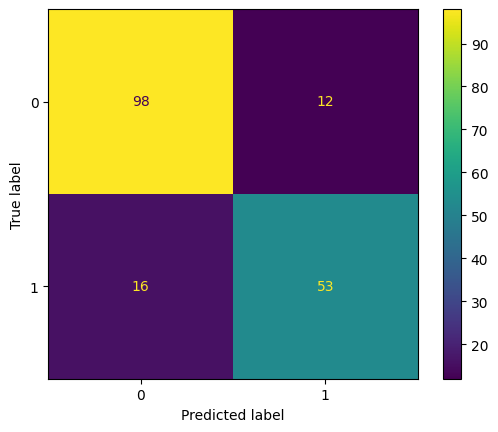

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
%matplotlib inline

cm = confusion_matrix(y_teste, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

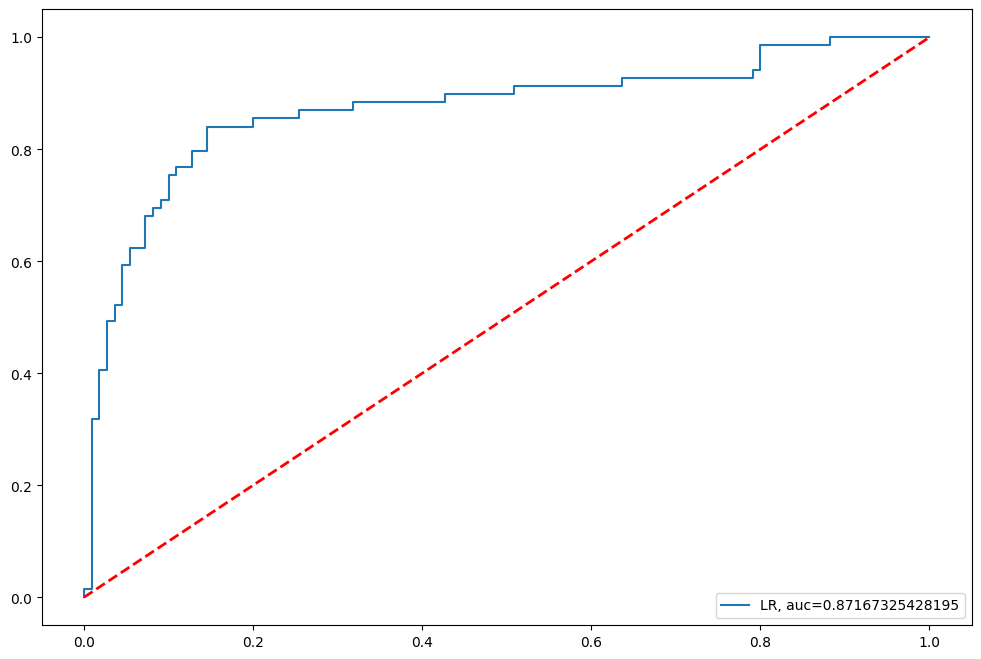

In [ ]:
y_pred_proba = modelo.predict_proba(X_teste)[::, 1]
fpr, tpr, _ = metrics.roc_curve(y_teste, y_pred_proba)
auc = metrics.roc_auc_score(y_teste, y_pred_proba)

plt.rcParams['figure.figsize'] = (12., 8.)
plt.plot(fpr, tpr, label="LR, auc=" + str(auc))
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--')
plt.legend(loc=4)


### Análise: regressão logística

| Métrica | Resultado |
|---|---|
| Acurácia | 0,844 |
| Precisão | 0,815 |
| Recall | 0,768 |
| F1 | 0,791 |

O modelo acertou cerca de **84 de cada 100** passageiros do teste. Ele é um pouco mais cuidadoso do que ousado: quando diz "sobreviveu", acerta mais (precisão 0,82), mas deixa escapar uma parte de quem sobreviveu (recall 0,77).

In [ ]:
df.groupby('sobreviveu').sexo.count()

,sexo
sobreviveu,
0,549
1,342


## 19. Modelo 2: árvore de decisão

A árvore funciona como uma série de perguntas de sim ou não ("é mulher?", "é da classe baixa?"). Limitamos a profundidade a 5 (`max_depth=5`) para ela não decorar os dados de treino, o que se chama *overfitting*.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
SEED = 42

In [ ]:
dt = DecisionTreeClassifier(max_depth=5, random_state=SEED)

In [ ]:

model = dt.fit(X_treino, y_treino)
y_pred = dt.predict(X_teste)

In [ ]:
print("Acurácia:", metrics.accuracy_score(y_teste, y_pred))
print("Precisão:", metrics.precision_score(y_teste, y_pred))
print("Recall:", metrics.recall_score(y_teste, y_pred))
print("F1:", metrics.f1_score(y_teste, y_pred))


Acurácia: 0.7932960893854749
Precisão: 0.8076923076923077
Recall: 0.6086956521739131
F1: 0.6942148760330579


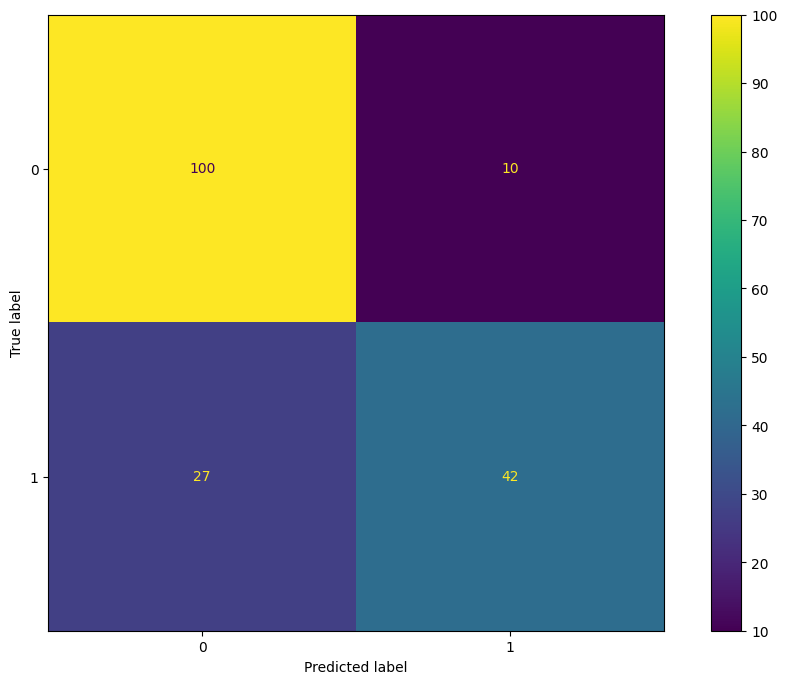

In [ ]:
cm = confusion_matrix(y_teste, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

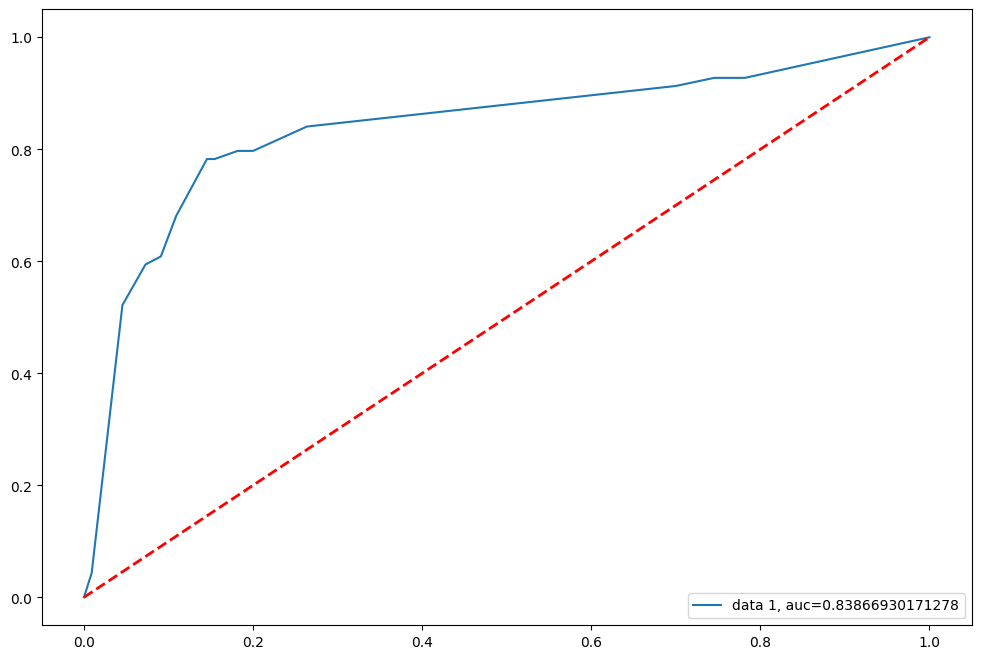

In [ ]:

y_pred_proba = dt.predict_proba(X_teste)[::, 1]
fpr, tpr, _ = metrics.roc_curve(y_teste, y_pred_proba)
auc = metrics.roc_auc_score(y_teste, y_pred_proba)

plt.rcParams['figure.figsize'] = (12., 8.)
plt.plot(fpr, tpr, label="data 1, auc=" + str(auc))
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--')
plt.legend(loc=4)

### Análise: árvore de decisão

| Métrica | Resultado |
|---|---|
| Acurácia | 0,793 |
| Precisão | 0,808 |
| Recall | 0,609 |
| F1 | 0,694 |

Ela acerta menos que a regressão. Repare no **recall de 0,61**: a árvore deixa passar quase 4 em cada 10 sobreviventes. É mais conservadora, e por isso perde para a regressão.

## 20. Modelo 3: floresta aleatória

Uma floresta é um **grupo de várias árvores** que votam juntas. Cada árvore vê um pedaço diferente dos dados, e a decisão final é a da maioria. Costuma ser mais estável que uma árvore sozinha.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(max_depth=5, random_state=SEED)

In [ ]:
model = rf.fit(X_treino, y_treino)
y_pred = rf.predict(X_teste)

print("Acurácia:", metrics.accuracy_score(y_teste, y_pred))
print("Precisão:", metrics.precision_score(y_teste, y_pred))
print("Recall:", metrics.recall_score(y_teste, y_pred))
print("F1:", metrics.f1_score(y_teste, y_pred))

Acurácia: 0.8100558659217877
Precisão: 0.7777777777777778
Recall: 0.7101449275362319
F1: 0.7424242424242424


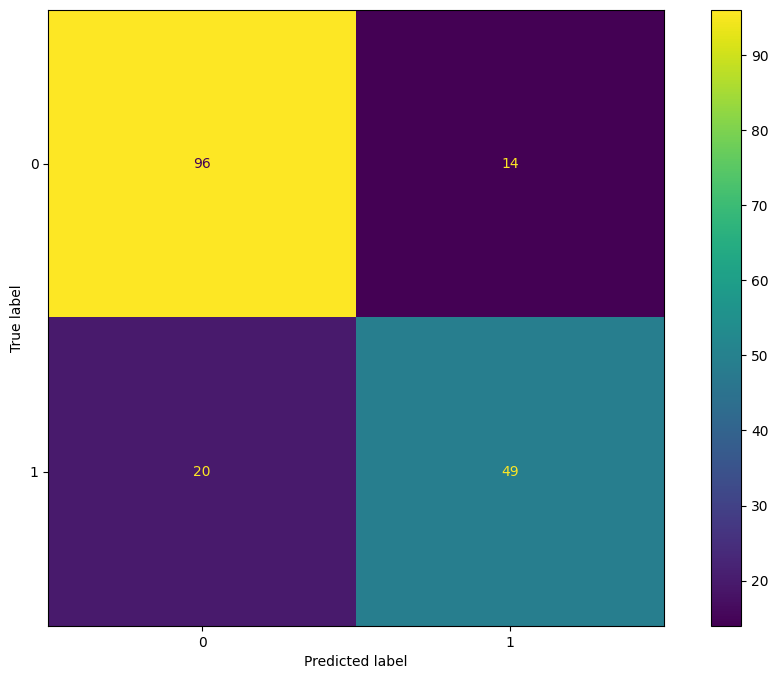

In [ ]:
cm = confusion_matrix(y_teste, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()


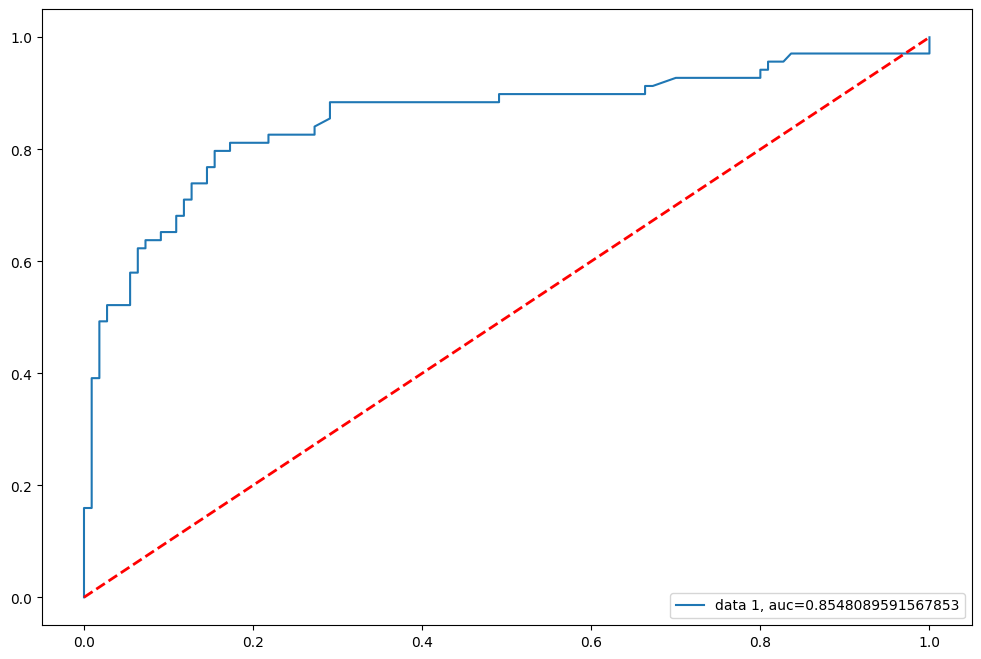

In [ ]:
y_pred_proba = rf.predict_proba(X_teste)[::, 1]
fpr, tpr, _ = metrics.roc_curve(y_teste, y_pred_proba)
auc = metrics.roc_auc_score(y_teste, y_pred_proba)

plt.rcParams['figure.figsize'] = (12., 8.)
plt.plot(fpr, tpr, label="data 1, auc=" + str(auc))
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--')
plt.legend(loc=4)

### Análise: floresta aleatória

| Métrica | Resultado |
|---|---|
| Acurácia | 0,810 |
| Precisão | 0,778 |
| Recall | 0,710 |
| F1 | 0,742 |

Melhorou em relação à árvore (acurácia de 0,79 para 0,81 e recall de 0,61 para 0,71), mas ficou abaixo da regressão logística.

## 21. Comparando os três modelos

| Modelo | Acurácia | Precisão | Recall | F1 |
|---|---|---|---|---|
| Regressão logística | 0,844 | 0,815 | 0,768 | 0,791 |
| Árvore de decisão | 0,793 | 0,808 | 0,609 | 0,694 |
| Floresta aleatória | 0,810 | 0,778 | 0,710 | 0,742 |

**O que vemos:** a regressão logística, que é a mais simples, foi a melhor em todas as métricas, exceto na precisão, em que a árvore ficou praticamente empatada.

**Um cuidado importante:** o teste tem só 179 passageiros. Cada passageiro a mais ou a menos acertado muda a acurácia em cerca de 0,6 ponto. Então uma diferença de 2 ou 3 pontos entre modelos pode ser **sorte do sorteio** do treino e teste, e não superioridade real. O placar oficial vai vir do Kaggle.

**Limitações para lembrar:**

- A idade foi preenchida com medianas calculadas usando todos os passageiros, inclusive os que ficaram no teste. É um vazamento pequeno, mas existe.
- Não ajustamos os parâmetros dos modelos (profundidade, número de árvores). Há margem para melhorar.

## 22. Do treino ao Kaggle

O Kaggle fornece **dois arquivos**:

- `train.csv`: 891 passageiros **com** a resposta (`Survived`). Foi com ele que treinamos e testamos.
- `test.csv`: 418 passageiros **sem** a resposta. Só o Kaggle sabe quem sobreviveu.

Nosso trabalho é prever a resposta desses 418 e enviar. O Kaggle compara com a verdade e devolve a acurácia, que é a nossa nota oficial.

**A regra de ouro:** o `test.csv` precisa passar pelo **mesmo tratamento** que o treino, na mesma ordem e com as mesmas regras. Se o modelo aprendeu com colunas em um formato, ele só entende colunas nesse mesmo formato.

Isso inclui:

1. Traduzir as colunas e inverter a classe.
2. Criar `titulo_pt`, `pais_embarque`, `viajou_sozinho`, `pessoas_no_bilhete` e `tarifa_por_pessoa`.
3. Preencher idade e tarifa vazias **com valores calculados no treino**, nunca no teste.
4. Aplicar `get_dummies` e deixar as colunas **idênticas e na mesma ordem** que as do `X`.

**Cuidados específicos do `test.csv`:**

- Tem 1 passageiro sem tarifa e cerca de 86 sem idade.
- Tem títulos que não existem no treino (como `Dona`). Isso pode criar uma coluna a mais ou a menos, e o modelo reclama. Resolvemos alinhando as colunas com `X.columns`.
- Não tem a coluna `Survived`. O que o modelo gera é a previsão.

### Passo 1: carregar o `test.csv`

Lemos o arquivo direto do CSV do Kaggle (e não pela planilha do Google, que estragou as tarifas do treino). Esperamos **418 linhas** e **11 colunas**, a mesma lista do treino, sem a coluna `Survived`. Também olhamos quais colunas têm valores vazios.

In [124]:
teste = pd.read_csv('test.csv')
print(teste.shape)   # esperado: (418, 11)

vazios = teste.isna().sum()
print(vazios[vazios > 0])

(418, 11)
Age       86
Fare       1
Cabin    327
dtype: int64


### Passo 2: a receita de preparo

Para o `teste` passar pelo mesmo tratamento do treino, juntamos todos os passos numa **função** chamada `preparar`. Ela recebe a tabela no formato do Kaggle e devolve as mesmas colunas do `X`. Os cuidados importantes:

- **Idade vazia:** usa a mediana por título e classe calculada **no treino** (a função `preencher_idade` que já criamos).
- **Tarifa vazia** (1 passageiro): usa a mediana da classe, também do treino.
- **Título `Dona`:** não existe no treino. Ele vira uma coluna que o modelo não conhece, e é descartada no alinhamento final.
- **Colunas:** ao final, `reindex(columns=X.columns)` garante as mesmas colunas, na mesma ordem.

In [127]:
def preparar(raw, referencia=None):
    """Aplica no Kaggle-format 'raw' o mesmo tratamento do treino e devolve a tabela com as colunas do X."""
    t = raw.rename(columns=colunas_pt).copy()

    # colunas básicas
    t['classe'] = t['classe'].map({1: 3, 2: 2, 3: 1})
    t['sexo'] = t['sexo'].replace({'male': 'Masculino', 'female': 'Feminino'})
    t['titulo'] = t['nome'].str.extract(r',\s*([^.]+)\.')
    t['titulo_pt'] = t['titulo'].map({**traducao, 'Dona': 'Dona'})
    t['idade'] = pd.to_numeric(t['idade'], errors='coerce')
    t['pais_embarque'] = t['porto_embarque'].fillna('').map(
        {'C': 'França', 'Q': 'Irlanda', 'S': 'Inglaterra', '': 'Desconhecido'})

    # tarifa (vazia -> mediana da classe, calculada no treino)
    t['tarifa_num'] = pd.to_numeric(t['tarifa'], errors='coerce')
    base = referencia if referencia is not None else t
    mediana_classe = base.groupby('classe')['tarifa_num'].median()
    t['tarifa_num'] = t['tarifa_num'].fillna(t['classe'].map(mediana_classe))

    # bilhete e família
    t['pessoas_no_bilhete'] = t.groupby('bilhete')['id_passageiro'].transform('count')
    t['tarifa_por_pessoa'] = t['tarifa_num'] / t['pessoas_no_bilhete']
    t['viajou_sozinho'] = ((t['irmaos_conjuge'] + t['pais_filhos'] + 1) == 1).astype(int)

    # idade preenchida (medianas do treino)
    cols = ['idade', 'titulo_pt', 'classe']
    if referencia is None:
        t['idade_preenchida'] = preencher_idade(t[cols])
    else:
        junto = pd.concat([referencia[cols], t[cols].assign(idade=np.nan)], ignore_index=True)
        chute = preencher_idade(junto).iloc[len(referencia):].values
        t['idade_preenchida'] = t['idade'].fillna(pd.Series(chute, index=t.index))

    # texto -> 0 e 1
    t = pd.get_dummies(t, columns=['sexo', 'titulo_pt', 'pais_embarque'], dtype=int)
    return t.reindex(columns=X.columns, fill_value=0)

print('Função criada!')

Função criada!


### Passo 3: conferindo a receita no treino

Antes de usar a receita no teste, fazemos uma prova real: aplicamos `preparar` no `train.csv` original e comparamos com o `X` que já usamos. Se a função estiver certa, o resultado precisa ser **idêntico**, coluna por coluna.

In [128]:
X_conferencia = preparar(pd.read_csv('train.csv'))

print('Mesmas colunas, na mesma ordem?', list(X_conferencia.columns) == list(X.columns))

diferenca = (X_conferencia.reset_index(drop=True).astype(float) - X.reset_index(drop=True).astype(float)).abs().max()
print('Colunas com diferença (o ideal é nenhuma):')
print(diferenca[diferenca > 1e-9] if (diferenca > 1e-9).any() else 'nenhuma, tudo igual!')

Mesmas colunas, na mesma ordem? True
Colunas com diferença (o ideal é nenhuma):
nenhuma, tudo igual!


### Passo 4: preparando o `teste`

Agora sim, a receita no `teste`. O parâmetro `referencia=df` diz que as medianas (de idade e de tarifa) devem ser calculadas **no treino**. Conferimos o tamanho (418 linhas e as mesmas 29 colunas do `X`) e se sobrou algum valor vazio.

In [131]:
X_kaggle = preparar(teste, referencia=df)

print(X_kaggle.shape)   # esperado: (418, 29)
print('Valores vazios:', X_kaggle.isna().sum().sum())
X_kaggle.head()

(418, 29)
Valores vazios: 0


,irmaos_conjuge,pais_filhos,classe,tarifa_num,idade_preenchida,pessoas_no_bilhete,tarifa_por_pessoa,viajou_sozinho,sexo_Feminino,sexo_Masculino,...,titulo_pt_Menino,titulo_pt_Reverendo,titulo_pt_Senhor,titulo_pt_Senhora,titulo_pt_Senhorita,titulo_pt_Sra./Srta.,pais_embarque_Desconhecido,pais_embarque_França,pais_embarque_Inglaterra,pais_embarque_Irlanda
0,0,0,1,7.8292,34.5,1,7.8292,1,0,1,...,0,0,1,0,0,0,0,0,0,1
1,1,0,1,7.0000,47.0,1,7.0000,0,1,0,...,0,0,0,1,0,0,0,0,1,0
2,0,0,2,9.6875,62.0,1,9.6875,1,0,1,...,0,0,1,0,0,0,0,0,0,1
3,0,0,1,8.6625,27.0,1,8.6625,1,0,1,...,0,0,1,0,0,0,0,0,1,0
4,1,1,1,12.2875,22.0,1,12.2875,0,1,0,...,0,0,0,1,0,0,0,0,1,0


### Passo 5: previsões e arquivo de envio

Para a versão final, treinamos a regressão logística (o melhor modelo no nosso teste) com **todos os 891 passageiros**, sem guardar 20% de fora, porque agora o "teste de verdade" é o do Kaggle. Depois o modelo prevê os 418 passageiros e montamos o `submission.csv`, com as colunas `PassengerId` e `Survived`.

In [132]:
modelo_final = LogisticRegression(max_iter=1000)
modelo_final.fit(X, y)

previsao = modelo_final.predict(X_kaggle)

envio = pd.DataFrame({'PassengerId': teste['PassengerId'], 'Survived': previsao})
envio.to_csv('submission.csv', index=False)

print(envio.shape)   # esperado: (418, 2)
print('Previstos como sobreviventes:', round(envio['Survived'].mean(), 3))
envio.head()

(418, 2)
Previstos como sobreviventes: 0.407


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


## 23. O arquivo de envio

O Kaggle pede um CSV com **duas colunas** e **418 linhas**:

| PassengerId | Survived |
|---|---|
| 892 | 0 |
| 893 | 1 |
| ... | ... |

O `PassengerId` precisa ser **o mesmo do `test.csv`**, e `Survived` é a previsão do nosso modelo (0 ou 1).

**Como enviar:** na página da competição "Titanic - Machine Learning from Disaster", clique em **Submit Predictions** e envie o arquivo `submission.csv`. O Kaggle calcula a pontuação na hora. Um modelo simples costuma ficar em torno de 0,75 a 0,79.

Essa nota é o nosso ponto de partida. Daqui em diante, cada ideia nova (novas colunas, ajuste dos modelos) pode ser enviada e comparada.